# How Neural Networks Learn: The Mechanics, the Maths and the Code

> **Who is this for:** learners who have trained a small network once (for example in [Start Here: PyTorch from Zero](00_start_here_pytorch_from_zero.ipynb)) and now want one place that explains *how each moving part works*: the loss, backprop, activations, initialisation, optimisers, learning-rate schedules, batches, normalisation, regularisation, stability tricks, number formats and memory. It also works as revision before exams and interviews.
>
> **What you will learn:** for every item you get **what it is**, **the maths** (in simple words first, then a formula), a **tiny code demo** and a **practical tip**.
> - the forward pass in matrix form (shapes, broadcasting, the batch dimension) and the computational graph
> - about 15 loss functions, including numerically stable cross-entropy, focal, InfoNCE, triplet and CTC
> - backpropagation: a 60-line scalar autograd engine, a vectorised MLP backward pass checked against `torch.autograd`, gradient checking
> - activations and their derivatives, initialisation maths, optimisers from scratch (SGD to AdamW), learning-rate finders and schedules
> - batches and gradient accumulation, BatchNorm / LayerNorm / RMSNorm / GroupNorm, regularisation, gradient clipping, residual connections
> - number formats (FP32, FP16, BF16, FP8), mixed precision, gradient checkpointing, a training-memory calculator and the 6ND FLOPs rule
> - generalisation in practice: bias-variance, universal approximation, double descent, loss landscapes
> - a complete PyTorch training loop with a diagnostics checklist
>
> **Prerequisites:** [Neural network fundamentals](01_neural_network_fundamentals.ipynb), [Calculus](../14_Mathematics/02_calculus.ipynb) (derivatives and the chain rule). Helpful: [Optimizers](02_optimizers.ipynb), [Neural networks from scratch in NumPy](18_neural_networks_from_scratch_numpy.ipynb), [Matrix calculus and autodiff from scratch](../14_Mathematics/11_matrix_calculus_and_autodiff_from_scratch.ipynb).
>
> **Time needed:** about 3-4 hours to read and play with. The notebook itself runs in about 1-2 minutes on a laptop CPU.
>
> **Runs on:** CPU only, no API key, no internet. Uses NumPy, SciPy, scikit-learn (toy data only), matplotlib and PyTorch (CPU).

This is a **reference** notebook: you do not have to read it top to bottom. Jump to the section you need. Where another notebook in this repo already teaches a topic in depth, we give the short version here and link to it.

## Contents

| # | Section | Deeper notebook in this repo |
|---|---|---|
| 1 | Neuron, layer, forward pass, computational graph | [01 fundamentals](01_neural_network_fundamentals.ipynb) |
| 2 | Loss functions (regression, classification, embeddings, sequences, ranking) | - |
| 3 | Backpropagation: chain rule, micrograd-style engine, vectorised backward, gradient checking | [18 from scratch](18_neural_networks_from_scratch_numpy.ipynb), [14/11 autodiff](../14_Mathematics/11_matrix_calculus_and_autodiff_from_scratch.ipynb) |
| 4 | Activations and their derivatives, dead ReLUs | [01 fundamentals](01_neural_network_fundamentals.ipynb) |
| 5 | Initialisation: variance maths, Xavier, He, orthogonal | [18 from scratch](18_neural_networks_from_scratch_numpy.ipynb) |
| 6 | Optimisers from scratch with trajectory plots; Lion, Adafactor, Muon, Shampoo; Newton and L-BFGS | [02 optimizers](02_optimizers.ipynb), [14/06 optimization](../14_Mathematics/06_optimization.ipynb) |
| 7 | Learning rate: too high / too low, LR finder, schedules, batch size scaling, parameter groups | - |
| 8 | Batches, epochs, gradient noise, gradient accumulation, shuffling | [11 distributed](11_distributed_training.ipynb) |
| 9 | Normalisation: BatchNorm, LayerNorm, RMSNorm, GroupNorm; pre-norm vs post-norm | [18 from scratch](18_neural_networks_from_scratch_numpy.ipynb) |
| 10 | Regularisation: L1/L2, weight decay, dropout, early stopping, augmentation, mixup, stochastic depth | - |
| 11 | Training stability: vanishing/exploding gradients, clipping, residuals, loss spikes, NaN debugging | [04 RNNs](04_rnn_lstm_gru.ipynb) |
| 12 | Numerics and efficiency: number formats, mixed precision, checkpointing, memory, FLOPs | [13 quantization](13_quantization_and_compression_advanced.ipynb), [11 distributed](11_distributed_training.ipynb) |
| 13 | Generalisation in practice: bias-variance, universal approximation, double descent, grokking, loss landscapes | - |
| 14 | A complete PyTorch training loop and a diagnostics checklist | [16 training pipeline](16_industry_pytorch_training_pipeline.ipynb) |
| - | Recap cheat sheet, interview questions, further reading | - |

## 0. Setup

We import NumPy (arrays), matplotlib (plots) and PyTorch (`torch`, a deep-learning library that can compute gradients for us). We fix the **random seed** (the starting point of the random number generator) so every run prints the same numbers.

In [1]:
import math, time, copy, os, tempfile, itertools, warnings
warnings.filterwarnings("ignore")                 # keep the output readable

import numpy as np                                # arrays and maths
import matplotlib.pyplot as plt                   # plots
import torch                                      # tensors + automatic gradients
import torch.nn as nn                             # layers
import torch.nn.functional as F                   # functional versions of losses/activations
from scipy.special import erf                     # used for the exact GELU formula

SEED = 0
np.random.seed(SEED)
rng = np.random.default_rng(SEED)                 # NumPy's modern random generator
torch.manual_seed(SEED)
torch.set_num_threads(4)                          # small, predictable CPU usage
plt.rcParams.update({"figure.figsize": (6, 3.2), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

T_START = time.time()                             # to report total run time at the end
print("torch", torch.__version__, "| numpy", np.__version__)

torch 2.15.0+cpu | numpy 2.5.4


## 1. Neuron, layer, forward pass and the computational graph

### 1.1 A single neuron

**What it is.** A **neuron** takes some input numbers, multiplies each by a **weight** (how important that input is), adds a **bias** (a constant offset), and passes the total through an **activation function** (a simple non-linear "squash").

**Simple analogy.** A judge scoring a dish: each criterion (taste, look, smell) gets a weight, the judge adds them up, adds a personal mood offset, and then turns the total into a final verdict.

**The maths.** For an input vector $x \in \mathbb{R}^d$, weights $w \in \mathbb{R}^d$ and bias $b$:

$$z = w^\top x + b = \sum_{i=1}^{d} w_i x_i + b, \qquad a = \phi(z)$$

$z$ is the **pre-activation** (the raw score) and $a$ is the **activation** (the output after the squash $\phi$).

### 1.2 A layer and a batch, in matrix form

A **layer** is many neurons side by side that all read the same input. A **batch** is a group of examples processed together. Stacking examples as rows of $X$ and neurons as columns of $W$:

$$Z = XW + b, \qquad A = \phi(Z)$$

| Symbol | Shape | Meaning |
|---|---|---|
| $X$ | $(B, d_\text{in})$ | $B$ examples, each with $d_\text{in}$ features. $B$ is the **batch dimension** |
| $W$ | $(d_\text{in}, d_\text{out})$ | one column of weights per neuron |
| $b$ | $(d_\text{out},)$ | one bias per neuron, **broadcast** (copied) to every row |
| $Z, A$ | $(B, d_\text{out})$ | one row per example, one column per neuron |

**Broadcasting** means NumPy/PyTorch automatically stretches a smaller array to match a bigger one when the trailing shapes line up, so `Z + b` adds the same bias row to every example without a loop.

**Practical tip.** PyTorch's `nn.Linear` stores the weight as `(d_out, d_in)` and computes `x @ W.T + b`. Same maths, transposed storage. When shapes do not match, print `.shape` of every tensor; it solves most bugs.

In [2]:
# A 2-layer network forward pass in NumPy: 4 examples, 3 features -> 5 hidden units -> 2 outputs
B, d_in, d_hidden, d_out = 4, 3, 5, 2
X  = rng.normal(size=(B, d_in))
W1 = rng.normal(size=(d_in, d_hidden)) * 0.5;  b1 = np.zeros(d_hidden)
W2 = rng.normal(size=(d_hidden, d_out)) * 0.5; b2 = np.zeros(d_out)

Z1 = X @ W1 + b1          # (4,3) @ (3,5) -> (4,5); b1 (5,) is broadcast to each of the 4 rows
A1 = np.maximum(Z1, 0)    # ReLU activation, same shape
Z2 = A1 @ W2 + b2         # (4,5) @ (5,2) -> (4,2): 2 output scores per example
for name, arr in [("X", X), ("W1", W1), ("Z1", Z1), ("W2", W2), ("Z2 (logits)", Z2)]:
    print(f"{name:12s} shape {arr.shape}")

# The same layer in PyTorch: nn.Linear keeps weight as (out, in) and computes x @ W.T + b
lin = nn.Linear(d_in, d_hidden)
with torch.no_grad():
    lin.weight.copy_(torch.tensor(W1.T)); lin.bias.zero_()
print("\nnn.Linear weight shape:", tuple(lin.weight.shape))
print("matches NumPy Z1:", np.allclose(lin(torch.tensor(X, dtype=torch.float32)).detach().numpy(), Z1, atol=1e-5))

X            shape (4, 3)
W1           shape (3, 5)
Z1           shape (4, 5)
W2           shape (5, 2)
Z2 (logits)  shape (4, 2)

nn.Linear weight shape: (5, 3)
matches NumPy Z1: True


### 1.3 The computational graph

**What it is.** A **computational graph** is a diagram of every small operation in the forward pass, with arrows showing which values feed which. Frameworks like PyTorch record this graph while your code runs (this is called **define-by-run**), then walk it backwards to compute gradients.

```mermaid
flowchart LR
    X[X] --> M1((matmul))
    W1[W1] --> M1
    M1 --> A1((+ b1))
    b1[b1] --> A1
    A1 --> R((ReLU))
    R --> M2((matmul))
    W2[W2] --> M2
    M2 --> A2((+ b2))
    b2[b2] --> A2
    A2 --> L((loss))
    Y[labels y] --> L
```

Each circle is an operation that knows two things: how to compute its output (forward) and how to turn "gradient of the loss with respect to my output" into "gradient with respect to my inputs" (backward). Section 3 builds this machinery by hand.

In [3]:
# PyTorch records the graph as you compute. Each result remembers the function that made it (grad_fn).
x = torch.tensor([1.0, 2.0])
w = torch.tensor([0.5, -1.0], requires_grad=True)
b = torch.tensor(0.1, requires_grad=True)
z = (w * x).sum() + b
a = torch.relu(z)
loss = (a - 1.0) ** 2
print("loss.grad_fn         :", loss.grad_fn)
print("its inputs come from :", [f[0] for f in loss.grad_fn.next_functions])
loss.backward()                # walk the graph backwards
print("dL/dw =", w.grad, " dL/db =", b.grad, "(zero because ReLU is off: z =", round(z.item(), 2), ")")

loss.grad_fn         : <PowBackward0 object at 0x76760802afb0>
its inputs come from : [<SubBackward0 object at 0x7675ba0582b0>]
dL/dw = tensor([0., 0.])  dL/db = tensor(0.) (zero because ReLU is off: z = -1.4 )


## 2. Loss functions

**What it is.** A **loss function** turns "how wrong is the model on this example" into one number. Training means changing the weights to make the average loss smaller, so the loss defines what "good" means.

**Simple analogy.** The loss is the scoring rule of a game. Change the rule and players (the model) change their strategy.

Notation: $y$ is the true target, $\hat y$ the prediction, $z$ a raw score called a **logit** (a score before softmax/sigmoid turns it into a probability), $p$ a predicted probability, $N$ the number of examples.

### 2.1 Regression losses: MSE, MAE, Huber

| Loss | Formula (per example, residual $r = \hat y - y$) | Gradient w.r.t. $\hat y$ | Use when |
|---|---|---|---|
| **MSE** (mean squared error, L2) | $r^2$ | $2r$ | default for regression; errors are roughly Gaussian |
| **MAE** (mean absolute error, L1) | $\lvert r\rvert$ | $\operatorname{sign}(r)$ | many outliers; you want the median, not the mean |
| **Huber** (smooth L1) | $\tfrac12 r^2$ if $\lvert r\rvert\le\delta$, else $\delta(\lvert r\rvert-\tfrac12\delta)$ | $r$ clipped to $[-\delta,\delta]$ | you want MSE near zero but robustness to outliers |

In words: MSE punishes big errors a lot (squared), so a single outlier can dominate. MAE treats all errors linearly, which is robust but has a constant-size gradient even near the answer. Huber is quadratic for small errors and linear for large ones.

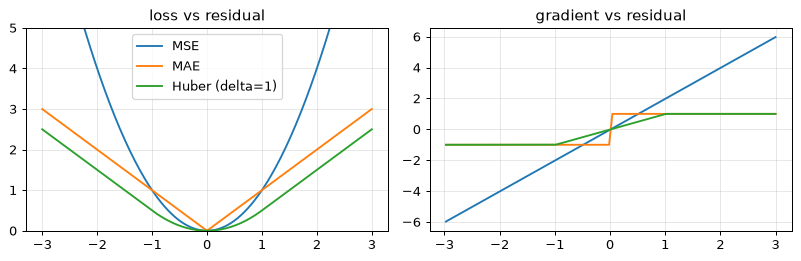

MSE    best constant prediction = 2.84
MAE    best constant prediction = 1.10
Huber  best constant prediction = 1.30
(MSE gives the mean, pulled by the outlier; MAE gives the median; Huber sits in between)


In [4]:
def mse(r):   return r ** 2
def mae(r):   return np.abs(r)
def huber(r, delta=1.0):
    return np.where(np.abs(r) <= delta, 0.5 * r ** 2, delta * (np.abs(r) - 0.5 * delta))

r = np.linspace(-3, 3, 200)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for f, name in [(mse, "MSE"), (mae, "MAE"), (huber, "Huber (delta=1)")]:
    ax[0].plot(r, f(r), label=name)
    ax[1].plot(r[1:], np.diff(f(r)) / np.diff(r), label=name)     # numerical gradient
ax[0].set_title("loss vs residual"); ax[1].set_title("gradient vs residual")
ax[0].legend(); ax[0].set_ylim(0, 5); plt.tight_layout(); plt.show()

# Outlier effect: the constant that minimises each loss on data with one big outlier
data = np.array([1.0, 1.2, 0.9, 1.1, 10.0])
cands = np.linspace(0, 10, 10001)
for f, name in [(mse, "MSE"), (mae, "MAE"), (huber, "Huber")]:
    best = cands[np.argmin([f(data - c).sum() for c in cands])]
    print(f"{name:6s} best constant prediction = {best:.2f}")
print("(MSE gives the mean, pulled by the outlier; MAE gives the median; Huber sits in between)")
# torch has them all: F.mse_loss, F.l1_loss, F.huber_loss (and F.smooth_l1_loss)

### 2.2 Classification: binary and categorical cross-entropy, computed stably

**Binary cross-entropy (BCE).** For a label $y \in \{0,1\}$ and logit $z$, the predicted probability is $p = \sigma(z) = 1/(1+e^{-z})$ (the **sigmoid**). BCE is the negative log of the probability given to the right answer:

$$\text{BCE}(z, y) = -\big[y \log p + (1-y)\log(1-p)\big]$$

**Categorical cross-entropy (CE).** For $K$ classes, logits $z \in \mathbb{R}^K$ and true class $c$, the **softmax** turns logits into probabilities $p_k = e^{z_k} / \sum_j e^{z_j}$, and

$$\text{CE}(z, c) = -\log p_c = -z_c + \log \sum_{j} e^{z_j}$$

**Why "with logits".** Computing `softmax` then `log` in two steps breaks for large logits: $e^{1000}$ overflows to infinity. The fix is the **log-sum-exp trick**: subtract the largest logit $m = \max_j z_j$ first, which does not change the answer:

$$\log \sum_j e^{z_j} = m + \log \sum_j e^{z_j - m}$$

Now the biggest exponent is $e^0 = 1$, so nothing overflows. For BCE the stable form is

$$\text{BCE}(z, y) = \max(z, 0) - z y + \log\big(1 + e^{-\lvert z\rvert}\big)$$

**Practical tip.** In PyTorch, give raw logits to `F.cross_entropy` / `nn.CrossEntropyLoss` (it applies log-softmax inside) and to `F.binary_cross_entropy_with_logits`. Do not put a softmax/sigmoid layer before them.

In [5]:
def logsumexp(z, axis=-1):
    m = np.max(z, axis=axis, keepdims=True)                  # subtract the max for stability
    return (m + np.log(np.sum(np.exp(z - m), axis=axis, keepdims=True))).squeeze(axis)

def cross_entropy(logits, labels):                           # logits (N,K), labels (N,) integers
    return np.mean(logsumexp(logits) - logits[np.arange(len(labels)), labels])

def bce_with_logits(z, y):
    return np.mean(np.maximum(z, 0) - z * y + np.log1p(np.exp(-np.abs(z))))

big = np.array([[1000.0, 1001.0, 1002.0]])
with np.errstate(over="ignore", invalid="ignore"):
    naive = np.exp(big) / np.exp(big).sum()                  # overflow -> inf/inf = nan
print("naive softmax of [1000,1001,1002]:", naive)
print("stable CE for class 2            :", cross_entropy(big, np.array([2])))

logits = rng.normal(size=(6, 4)) * 3; labels = rng.integers(0, 4, size=6)
print("our CE   :", round(cross_entropy(logits, labels), 6),
      "| torch CE:", round(F.cross_entropy(torch.tensor(logits), torch.tensor(labels)).item(), 6))
z = np.array([-50.0, -2.0, 0.0, 3.0, 80.0]); y = np.array([0, 1, 1, 0, 1.0])
print("our BCE  :", round(bce_with_logits(z, y), 6),
      "| torch BCE:", round(F.binary_cross_entropy_with_logits(torch.tensor(z), torch.tensor(y)).item(), 6))

naive softmax of [1000,1001,1002]: [[nan nan nan]]
stable CE for class 2            : 0.40760596444442854
our CE   : 2.612889 | torch CE: 2.612889
our BCE  : 1.173733 | torch BCE: 1.173733


### 2.3 Label smoothing and focal loss

**Label smoothing.** Instead of a one-hot target ("100% class $c$"), use a softened target: $q_k = (1-\varepsilon)\,\mathbb{1}[k=c] + \varepsilon/K$. With $\varepsilon = 0.1$ the model is asked for 90% plus a share of the rest, so it stops pushing logits to infinity. This often improves **calibration** (probabilities that match real-world frequencies) and is standard in image classifiers and many transformer recipes.

$$\text{CE}_\text{ls} = -\sum_k q_k \log p_k$$

**Focal loss** (Lin et al., 2017, for object detection with many easy background boxes). Let $p_t$ be the probability of the true class. Focal loss multiplies CE by $(1-p_t)^\gamma$, so examples the model already gets right ($p_t \to 1$) contribute almost nothing and training focuses on hard ones:

$$\text{FL}(p_t) = -\alpha\,(1-p_t)^\gamma \log p_t, \quad \gamma \approx 2$$

Use it for heavy class imbalance (detection, rare-event classification). For mild imbalance, class weights in plain CE are simpler.

In [6]:
def ce_label_smoothing(logits, labels, eps=0.1):
    N, K = logits.shape
    q = np.full((N, K), eps / K); q[np.arange(N), labels] += 1 - eps     # smoothed targets
    log_p = logits - logsumexp(logits)[:, None]                          # log-softmax
    return np.mean(-(q * log_p).sum(axis=1))

print("label smoothing ours :", round(ce_label_smoothing(logits, labels), 6))
print("label smoothing torch:", round(F.cross_entropy(torch.tensor(logits), torch.tensor(labels), label_smoothing=0.1).item(), 6))

def focal_weight(p_t, gamma): return (1 - p_t) ** gamma
print("\nHow much each example counts relative to plain CE:")
for p_t in [0.1, 0.5, 0.9, 0.99]:
    print(f"  p_true={p_t:4.2f}  CE={-np.log(p_t):5.3f}   focal(gamma=2)={-focal_weight(p_t, 2) * np.log(p_t):7.5f}"
          f"   weight={focal_weight(p_t, 2):.4f}")

label smoothing ours : 2.658554
label smoothing torch: 2.658554

How much each example counts relative to plain CE:
  p_true=0.10  CE=2.303   focal(gamma=2)=1.86509   weight=0.8100
  p_true=0.50  CE=0.693   focal(gamma=2)=0.17329   weight=0.2500
  p_true=0.90  CE=0.105   focal(gamma=2)=0.00105   weight=0.0100
  p_true=0.99  CE=0.010   focal(gamma=2)=0.00000   weight=0.0001


### 2.4 Hinge loss and KL divergence

**Hinge loss** (used by support vector machines). Labels are $y \in \{-1, +1\}$ and the score is $s$. There is no loss once the example is on the right side with a **margin** (a safety gap) of at least 1:

$$\text{hinge}(s, y) = \max(0,\; 1 - y\,s)$$

The multi-class version (`nn.MultiMarginLoss`) asks the true class score to beat every other score by the margin.

**KL divergence** measures how different a predicted distribution $q$ is from a target distribution $p$ (it is zero only when they are equal, and it is not symmetric):

$$D_\text{KL}(p\,\|\,q) = \sum_k p_k \log \frac{p_k}{q_k}$$

Cross-entropy equals entropy plus KL: $H(p, q) = H(p) + D_\text{KL}(p\|q)$, so with fixed targets minimising CE and minimising KL are the same thing. KL appears in **knowledge distillation** (a small student copies a big teacher's soft probabilities), **VAEs** and **RLHF** (keeping a fine-tuned model close to the original). See [information theory](../14_Mathematics/05_information_theory.ipynb).

**Practical tip.** `F.kl_div(input, target)` expects `input` as **log-probabilities** of $q$ and `target` as probabilities of $p$. Use `reduction="batchmean"` to get the true mathematical average.

In [7]:
s = np.array([2.0, 0.5, -0.3, -2.0]); yy = np.array([1, 1, 1, -1])
print("hinge per example:", np.maximum(0, 1 - yy * s), "(0 once y*s >= 1)")

p = np.array([[0.7, 0.2, 0.1]]); q_logits = np.array([[1.0, 0.5, 0.2]])
log_q = q_logits - logsumexp(q_logits)[:, None]
kl_ours = np.sum(p * (np.log(p) - log_q))
kl_torch = F.kl_div(torch.tensor(log_q), torch.tensor(p), reduction="batchmean").item()
H_pq = -np.sum(p * log_q); H_p = -np.sum(p * np.log(p))
print(f"KL ours={kl_ours:.6f}  torch={kl_torch:.6f}   check H(p,q) - H(p) = {H_pq - H_p:.6f}")

hinge per example: [0.  0.5 1.3 0. ] (0 once y*s >= 1)
KL ours=0.098876  torch=0.098876   check H(p,q) - H(p) = 0.098876


### 2.5 Embedding losses: contrastive / InfoNCE and triplet

These losses do not predict labels. They shape an **embedding space** (a space of vectors where similar things are close) by comparing examples to each other.

**InfoNCE** (the loss behind CLIP, SimCLR and most retrieval models). Take $N$ pairs $(u_i, v_i)$ that belong together (an image and its caption, a query and its answer). Every other $v_j$ in the batch is a **negative** (a non-matching example). With cosine similarity $s_{ij}$ and a **temperature** $\tau$ (a number that sharpens or softens the softmax):

$$\mathcal{L}_\text{InfoNCE} = -\frac1N \sum_i \log \frac{\exp(s_{ii}/\tau)}{\sum_{j=1}^{N} \exp(s_{ij}/\tau)}$$

In words: a cross-entropy where "the right class" for row $i$ is column $i$. That is exactly how it is coded.

**Triplet loss** (FaceNet). With an **anchor** $a$, a **positive** $p$ (same identity) and a **negative** $n$ (different identity), require the positive to be closer than the negative by a margin $m$:

$$\mathcal{L}_\text{triplet} = \max\big(0,\; d(a,p) - d(a,n) + m\big)$$

**Practical tip.** Contrastive losses need many negatives, so bigger batches help. Triplet loss needs **hard negative mining** (choosing negatives that are currently close), otherwise most triplets already have zero loss. See [self-supervised learning](09_self_supervised_learning.ipynb).

In [8]:
def info_nce(u, v, tau=0.1):
    u = F.normalize(u, dim=1); v = F.normalize(v, dim=1)   # unit length -> dot product = cosine similarity
    sim = u @ v.T / tau                                     # (N, N) similarity matrix
    return F.cross_entropy(sim, torch.arange(len(u)))       # "correct class" of row i is column i

torch.manual_seed(0)
u = torch.randn(16, 32)
v_matched = u + 0.3 * torch.randn(16, 32)                   # v_i is a noisy copy of u_i: good pairs
v_random  = torch.randn(16, 32)                             # unrelated
print(f"InfoNCE matched pairs: {info_nce(u, v_matched):.3f}   random pairs: {info_nce(u, v_random):.3f}"
      f"   (chance level = log(16) = {math.log(16):.3f})")

a, pos, neg = torch.randn(8, 4), torch.randn(8, 4), torch.randn(8, 4)
ours = torch.clamp((a - pos).norm(dim=1) - (a - neg).norm(dim=1) + 1.0, min=0).mean()
print(f"triplet ours={ours:.4f}  torch={nn.TripletMarginLoss(margin=1.0)(a, pos, neg):.4f}  (torch adds a tiny eps inside the distance)")

InfoNCE matched pairs: 0.005   random pairs: 5.002   (chance level = log(16) = 2.773)
triplet ours=1.5653  torch=1.5653  (torch adds a tiny eps inside the distance)


### 2.6 CTC (brief) and ranking losses (brief)

**CTC, Connectionist Temporal Classification** (Graves et al., 2006). Used in speech and handwriting recognition when the input (say 100 audio frames) is longer than the output ("cat", 3 letters) and you do not know which frame matches which letter. The model outputs a distribution over letters plus a special **blank** symbol at every frame. An **alignment** is one letter-or-blank per frame; it "collapses" to text by merging repeats and then removing blanks (`c c - a - t t` becomes `cat`). CTC sums the probability of **every** alignment that collapses to the target:

$$\mathcal{L}_\text{CTC} = -\log \sum_{\pi \,:\, \text{collapse}(\pi) = y} \prod_{t=1}^{T} p_t(\pi_t)$$

The sum is computed efficiently with dynamic programming. Below we check `F.ctc_loss` against brute-force enumeration on a tiny case.

**Ranking losses** (search, recommendation). They care about order, not exact values.
- **Pairwise (RankNet / BPR):** for an item $i$ that should rank above $j$, $\mathcal{L} = \log(1 + e^{-(s_i - s_j)})$.
- **Margin ranking:** $\max(0, m - (s_i - s_j))$ (`nn.MarginRankingLoss`).
- **Listwise (ListNet):** cross-entropy between the softmax of true relevances and the softmax of predicted scores over the whole list.

In [9]:
# CTC: T=4 frames, alphabet {0: blank, 1: 'a', 2: 'b'}, target "ab"
torch.manual_seed(1)
T, C = 4, 3
log_probs = torch.randn(T, 1, C).log_softmax(dim=2)        # shape (T, batch=1, C)
target = torch.tensor([[1, 2]])
ctc = F.ctc_loss(log_probs, target, input_lengths=torch.tensor([T]), target_lengths=torch.tensor([2]),
                 reduction="sum")                           # default 'mean' also divides by target length

def collapse(path):                                        # merge repeats, then drop blanks
    merged = [k for i, k in enumerate(path) if i == 0 or k != path[i - 1]]
    return [k for k in merged if k != 0]

probs = log_probs[:, 0, :].exp()
total, n_valid = 0.0, 0
for path in itertools.product(range(C), repeat=T):         # all 3^4 = 81 alignments
    if collapse(list(path)) == [1, 2]:
        total += torch.prod(torch.stack([probs[t, k] for t, k in enumerate(path)])).item(); n_valid += 1
print(f"{n_valid} alignments collapse to 'ab'. brute force -log P = {-math.log(total):.5f}, F.ctc_loss = {ctc.item():.5f}")

# Ranking: scores for 4 documents, relevance says doc0 > doc1 > doc2 > doc3
scores = torch.tensor([2.0, 2.5, 0.1, -1.0]); relevance = torch.tensor([3.0, 2.0, 1.0, 0.0])
pairs = [(i, j) for i in range(4) for j in range(4) if relevance[i] > relevance[j]]
ranknet = torch.stack([F.softplus(-(scores[i] - scores[j])) for i, j in pairs]).mean()   # log(1+e^-(si-sj))
listnet = -(F.softmax(relevance, 0) * F.log_softmax(scores, 0)).sum()
print(f"pairwise RankNet loss = {ranknet:.4f} (mostly from the wrongly ordered pair doc0 vs doc1), ListNet loss = {listnet:.4f}")

15 alignments collapse to 'ab'. brute force -log P = 1.55551, F.ctc_loss = 1.55551
pairwise RankNet loss = 0.2610 (mostly from the wrongly ordered pair doc0 vs doc1), ListNet loss = 1.1900


### 2.7 Which loss should I pick?

| Task | First choice | Alternatives |
|---|---|---|
| Regression | MSE | MAE or Huber with outliers; quantile (pinball) loss for prediction intervals |
| Binary / multi-label classification | BCE with logits (one sigmoid per label) | focal loss for heavy imbalance; `pos_weight` for mild imbalance |
| Multi-class classification | cross-entropy with logits | + label smoothing 0.1; class weights; focal |
| Language modelling | cross-entropy over the vocabulary (next-token prediction) | + z-loss (a small penalty on $\log\sum e^{z}$) for stability at large scale |
| Distillation / matching distributions | KL divergence (often on temperature-softened logits) | - |
| Embeddings / retrieval | InfoNCE with in-batch negatives | triplet with hard negatives; multiple-negatives ranking loss |
| Sequence labelling without alignment | CTC | attention-based sequence-to-sequence with CE |
| Search / recommendation order | pairwise (BPR / RankNet) | listwise (ListNet, LambdaRank-style) |
| SVM-style max margin | hinge | squared hinge |

## 3. Backpropagation

### 3.1 The chain rule

**What it is.** **Backpropagation** ("backprop") is an efficient way to compute the gradient of the loss with respect to every weight: the derivative that says "if I nudge this weight up a tiny bit, how much does the loss change?". It is just the **chain rule** of calculus applied from the loss backwards through the computational graph.

**Simple analogy.** A relay of blame. The loss tells the last layer how unhappy it is; each layer passes a share of that blame to whatever fed it, scaled by how sensitive it was.

**The maths.** If $L$ depends on $w$ through a chain $w \to z \to a \to L$, then

$$\frac{\partial L}{\partial w} = \frac{\partial L}{\partial a}\cdot\frac{\partial a}{\partial z}\cdot\frac{\partial z}{\partial w}$$

When a value feeds several later operations, its gradient is the **sum** of the gradients arriving from each path. Every backward step multiplies the incoming gradient (called the **upstream gradient**) by the local derivative of that operation.

Example from Section 1.3 with ReLU on: $z = w^\top x + b$, $a = \text{relu}(z)$, $L = (a-1)^2$. Then $\partial L/\partial a = 2(a-1)$, $\partial a/\partial z = 1$ if $z>0$ else 0, $\partial z/\partial w_i = x_i$.

The cost of backprop is roughly **2x the forward pass**, no matter how many weights there are. That is why it beats computing one derivative per weight by finite differences. For the full matrix-calculus treatment and forward-mode vs reverse-mode autodiff see [14/11 matrix calculus and autodiff](../14_Mathematics/11_matrix_calculus_and_autodiff_from_scratch.ipynb).

### 3.2 A tiny scalar autograd engine (micrograd style)

Below is a complete reverse-mode autodiff engine for scalars in about 60 lines, in the style of Andrej Karpathy's *micrograd*. Each `Value` stores its number, its gradient, its parents and a small `_backward` function that applies the local chain-rule step. `backward()` sorts the graph so every node is processed after everything that depends on it (a **topological order**), then runs the steps in reverse.

In [10]:
class Value:
    # A scalar that remembers how it was computed, so it can backpropagate.
    def __init__(self, data, _parents=(), _op=""):
        self.data, self.grad = float(data), 0.0
        self._parents, self._op = _parents, _op
        self._backward = lambda: None              # leaf nodes have nothing to pass back

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def _backward():                           # d(a+b)/da = 1, d(a+b)/db = 1
            self.grad += out.grad; other.grad += out.grad
        out._backward = _backward; return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def _backward():                           # d(ab)/da = b, d(ab)/db = a
            self.grad += other.data * out.grad; other.grad += self.data * out.grad
        out._backward = _backward; return out

    def __pow__(self, k):                          # k is a plain number
        out = Value(self.data ** k, (self,), f"**{k}")
        def _backward(): self.grad += k * self.data ** (k - 1) * out.grad
        out._backward = _backward; return out

    def tanh(self):
        t = math.tanh(self.data); out = Value(t, (self,), "tanh")
        def _backward(): self.grad += (1 - t * t) * out.grad
        out._backward = _backward; return out

    def relu(self):
        out = Value(max(0.0, self.data), (self,), "relu")
        def _backward(): self.grad += (self.data > 0) * out.grad
        out._backward = _backward; return out

    def exp(self):
        e = math.exp(self.data); out = Value(e, (self,), "exp")
        def _backward(): self.grad += e * out.grad
        out._backward = _backward; return out

    def log(self):
        out = Value(math.log(self.data), (self,), "log")
        def _backward(): self.grad += (1 / self.data) * out.grad
        out._backward = _backward; return out

    def backward(self):
        order, seen = [], set()
        def visit(v):                              # depth-first topological sort
            if v not in seen:
                seen.add(v)
                for p in v._parents: visit(p)
                order.append(v)
        visit(self)
        self.grad = 1.0                            # dL/dL = 1
        for v in reversed(order): v._backward()

    # small conveniences so normal Python maths works
    def __neg__(self): return self * -1
    def __sub__(self, other): return self + (-other)
    def __rsub__(self, other): return (-self) + other
    def __truediv__(self, other): return self * (other ** -1 if isinstance(other, Value) else 1.0 / other)
    __radd__, __rmul__ = __add__, __mul__
    def __repr__(self): return f"Value(data={self.data:.4f}, grad={self.grad:.4f})"

In [11]:
# Check our engine against PyTorch on a small expression that reuses a variable (so gradients must add up)
a, b = Value(-2.0), Value(3.0)
c = a * b + b ** 2              # b is used twice
d = (c.tanh() + (a * 0.5).exp()).log() - c / 10
d.backward()

ta = torch.tensor(-2.0, dtype=torch.float64, requires_grad=True)
tb = torch.tensor(3.0, dtype=torch.float64, requires_grad=True)
tc = ta * tb + tb ** 2
td = (torch.tanh(tc) + torch.exp(ta * 0.5)).log() - tc / 10
td.backward()
print(f"ours : d={d.data:.6f}  dd/da={a.grad:.6f}  dd/db={b.grad:.6f}")
print(f"torch: d={td.item():.6f}  dd/da={ta.grad.item():.6f}  dd/db={tb.grad.item():.6f}")

ours : d=0.009640  dd/da=-0.143325  dd/db=-0.371045
torch: d=0.009640  dd/da=-0.143325  dd/db=-0.371045


In [12]:
# Train a tiny MLP made of Values: 2 inputs -> 4 tanh -> 1 output, on 4 points (XOR-like targets)
import random
random.seed(0)
class Neuron:
    def __init__(self, n_in): self.w = [Value(random.uniform(-1, 1)) for _ in range(n_in)]; self.b = Value(0.0)
    def __call__(self, x): return sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
    def params(self): return self.w + [self.b]

hidden = [Neuron(2) for _ in range(4)]; out_neuron = Neuron(4)
params = [p for n in hidden + [out_neuron] for p in n.params()]
def model(x): return out_neuron([h(x).tanh() for h in hidden])

xs = [[0, 0], [0, 1], [1, 0], [1, 1]]; ys = [-1, 1, 1, -1]
for step in range(100):
    loss = sum(((model(x) - y) ** 2 for x, y in zip(xs, ys)), Value(0.0)) / 4
    for p in params: p.grad = 0.0           # gradients accumulate, so reset them every step
    loss.backward()
    for p in params: p.data -= 0.3 * p.grad # plain gradient descent
    if step % 25 == 0 or step == 99: print(f"step {step:2d}  loss {loss.data:.4f}")
print("predictions:", [round(model(x).data, 2) for x in xs], "targets:", ys)

step  0  loss 1.0429
step 25  loss 0.7211
step 50  loss 0.0924
step 75  loss 0.0502
step 99  loss 0.0002
predictions: [-0.99, 0.99, 0.99, -0.98] targets: [-1, 1, 1, -1]


### 3.3 The vectorised backward pass of a 2-layer MLP

Real code works with whole matrices. For a batch $X$ (shape $B\times D$), a ReLU hidden layer and softmax cross-entropy:

$$Z_1 = XW_1 + b_1,\quad H = \text{relu}(Z_1),\quad Z_2 = HW_2 + b_2,\quad P = \text{softmax}(Z_2),\quad L = -\tfrac1B\sum_i \log P_{i,y_i}$$

Going backwards (each line is one chain-rule step; $Y$ is the one-hot label matrix and $\odot$ is element-wise multiplication):

$$\begin{aligned}
\frac{\partial L}{\partial Z_2} &= \tfrac1B (P - Y) && \text{(softmax + CE combine into this neat form)}\\
\frac{\partial L}{\partial W_2} &= H^\top \frac{\partial L}{\partial Z_2}, \qquad \frac{\partial L}{\partial b_2} = \textstyle\sum_\text{rows} \frac{\partial L}{\partial Z_2}\\
\frac{\partial L}{\partial H} &= \frac{\partial L}{\partial Z_2} W_2^\top\\
\frac{\partial L}{\partial Z_1} &= \frac{\partial L}{\partial H} \odot \mathbb{1}[Z_1 > 0]\\
\frac{\partial L}{\partial W_1} &= X^\top \frac{\partial L}{\partial Z_1}, \qquad \frac{\partial L}{\partial b_1} = \textstyle\sum_\text{rows} \frac{\partial L}{\partial Z_1}
\end{aligned}$$

**Shape rule that catches most mistakes:** the gradient of a tensor always has the same shape as the tensor itself. $W_1$ is $D\times H$, so $X^\top$ ($D\times B$) times $\partial L/\partial Z_1$ ($B\times H$) is the only product that fits. Biases are broadcast over the batch in the forward pass, so their gradients are **summed** over the batch in the backward pass.

In [13]:
def mlp_forward_backward(X, y, W1, b1, W2, b2):
    B = X.shape[0]
    # forward
    Z1 = X @ W1 + b1; H = np.maximum(Z1, 0); Z2 = H @ W2 + b2
    P = np.exp(Z2 - logsumexp(Z2)[:, None])              # stable softmax
    loss = -np.mean(np.log(P[np.arange(B), y]))
    # backward
    Y = np.eye(W2.shape[1])[y]                           # one-hot labels
    dZ2 = (P - Y) / B
    dW2 = H.T @ dZ2;  db2 = dZ2.sum(axis=0)
    dH  = dZ2 @ W2.T
    dZ1 = dH * (Z1 > 0)
    dW1 = X.T @ dZ1;  db1 = dZ1.sum(axis=0)
    return loss, dict(W1=dW1, b1=db1, W2=dW2, b2=db2)

D, Hd, K, Bn = 5, 8, 3, 16
Xb = rng.normal(size=(Bn, D)); yb = rng.integers(0, K, size=Bn)
P0 = dict(W1=rng.normal(size=(D, Hd)) * 0.5, b1=rng.normal(size=Hd) * 0.1,
          W2=rng.normal(size=(Hd, K)) * 0.5, b2=np.zeros(K))
loss_np, grads_np = mlp_forward_backward(Xb, yb, **P0)

# Same network in torch, gradients by autograd
tP = {k: torch.tensor(v, requires_grad=True) for k, v in P0.items()}           # float64
logits_t = torch.relu(torch.tensor(Xb) @ tP["W1"] + tP["b1"]) @ tP["W2"] + tP["b2"]
loss_t = F.cross_entropy(logits_t, torch.tensor(yb)); loss_t.backward()
print(f"loss numpy {loss_np:.8f}  torch {loss_t.item():.8f}")
for k in P0:
    print(f"  d{k:2s} shape {str(grads_np[k].shape):7s} max |numpy - torch| = {np.abs(grads_np[k] - tP[k].grad.numpy()).max():.2e}")

loss numpy 1.95429056  torch 1.95429056
  dW1 shape (5, 8)  max |numpy - torch| = 1.11e-16
  db1 shape (8,)    max |numpy - torch| = 1.11e-16
  dW2 shape (8, 3)  max |numpy - torch| = 5.55e-17
  db2 shape (3,)    max |numpy - torch| = 5.55e-17


### 3.4 Gradient checking

**What it is.** A test that compares your analytic gradient with a numerical estimate from the definition of a derivative. The **centred difference** is accurate to order $\epsilon^2$:

$$\frac{\partial L}{\partial \theta_i} \approx \frac{L(\theta + \epsilon e_i) - L(\theta - \epsilon e_i)}{2\epsilon}$$

Compare with the **relative error** $\dfrac{|g_\text{analytic} - g_\text{numeric}|}{\max(|g_\text{analytic}|, |g_\text{numeric}|, 10^{-12})}$. In float64 with $\epsilon \approx 10^{-6}$, values around $10^{-7}$ or smaller mean "correct"; $10^{-2}$ or larger means a bug.

**Practical tips.** Always gradient-check in **float64** (float32 rounding swamps the estimate). Turn off dropout and other randomness while checking. Kinks (ReLU at exactly 0) can give a false alarm on a few entries. A per-layer gradient check of every layer type is in [18 from scratch, Section 3](18_neural_networks_from_scratch_numpy.ipynb). PyTorch has `torch.autograd.gradcheck` for custom functions.

In [14]:
def grad_check(param_name, n_checks=6, eps=1e-6):
    worst = 0.0
    for _ in range(n_checks):
        idx = tuple(rng.integers(0, s) for s in P0[param_name].shape)    # a random entry
        plus = {k: v.copy() for k, v in P0.items()};  plus[param_name][idx] += eps
        minus = {k: v.copy() for k, v in P0.items()}; minus[param_name][idx] -= eps
        numeric = (mlp_forward_backward(Xb, yb, **plus)[0] - mlp_forward_backward(Xb, yb, **minus)[0]) / (2 * eps)
        analytic = grads_np[param_name][idx]
        worst = max(worst, abs(analytic - numeric) / max(abs(analytic), abs(numeric), 1e-12))
    return worst

for k in P0:
    print(f"{k:3s} worst relative error over 6 random entries: {grad_check(k):.2e}")

W1  worst relative error over 6 random entries: 2.93e-08


b1  worst relative error over 6 random entries: 1.53e-07
W2  worst relative error over 6 random entries: 3.20e-09
b2  worst relative error over 6 random entries: 1.00e-08


## 4. Activation functions and their derivatives

**What it is.** An **activation function** is the non-linear function applied after each linear layer. Without it, a stack of linear layers collapses into one linear layer ($W_2(W_1x) = (W_2W_1)x$), so the network could only draw straight lines.

**Simple analogy.** A dimmer switch with a personality: some cut off below zero (ReLU), some squash everything into a range (sigmoid, tanh), some let a bit of negative signal leak through (Leaky ReLU, GELU).

| Name | $\phi(x)$ | $\phi'(x)$ | Where you see it |
|---|---|---|---|
| Sigmoid $\sigma$ | $\dfrac{1}{1+e^{-x}}$ | $\sigma(x)(1-\sigma(x))$, at most 0.25 | binary outputs, gates in LSTMs |
| Tanh | $\tanh x$ | $1-\tanh^2 x$ | RNNs, older MLPs |
| ReLU | $\max(0,x)$ | 1 if $x>0$ else 0 | default for CNNs and MLPs |
| Leaky ReLU | $x$ if $x>0$ else $\alpha x$ | 1 or $\alpha$ (e.g. 0.01) | avoids dead units |
| ELU | $x$ if $x>0$ else $\alpha(e^x-1)$ | 1 or $\alpha e^x$ | smooth negative side |
| GELU | $x\,\Phi(x)$, $\Phi$ = standard normal CDF | $\Phi(x) + x\,\varphi(x)$ | BERT, GPT-2, ViT |
| SiLU / Swish | $x\,\sigma(x)$ | $\sigma(x)\big(1 + x(1-\sigma(x))\big)$ | EfficientNet; inside SwiGLU |
| Softmax | $p_k = e^{x_k}/\sum_j e^{x_j}$ | Jacobian $\operatorname{diag}(p) - pp^\top$ | turning scores into class probabilities |

GELU is often computed with the tanh approximation $0.5x\big(1+\tanh(\sqrt{2/\pi}(x+0.044715x^3))\big)$.

**Why the derivative matters.** Backprop multiplies by $\phi'$ at every layer. Sigmoid's derivative is at most 0.25, so ten sigmoid layers can shrink the gradient by $0.25^{10} \approx 10^{-6}$ (vanishing gradients, Section 11). ReLU's derivative is exactly 1 on the active side, which is a big reason deep ReLU networks train well.

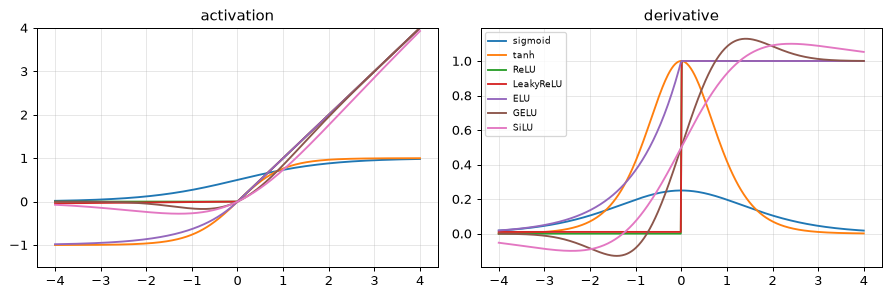

sigmoid    max |our derivative - autograd| = 2.8e-17
tanh       max |our derivative - autograd| = 2.7e-16
ReLU       max |our derivative - autograd| = 0.0e+00
LeakyReLU  max |our derivative - autograd| = 0.0e+00
ELU        max |our derivative - autograd| = 1.1e-16
GELU       max |our derivative - autograd| = 4.4e-16
SiLU       max |our derivative - autograd| = 2.2e-16


In [15]:
sig = lambda x: 1 / (1 + np.exp(-x))
acts = {   # name: (function, derivative)
    "sigmoid":    (sig, lambda x: sig(x) * (1 - sig(x))),
    "tanh":       (np.tanh, lambda x: 1 - np.tanh(x) ** 2),
    "ReLU":       (lambda x: np.maximum(0, x), lambda x: (x > 0).astype(float)),
    "LeakyReLU":  (lambda x: np.where(x > 0, x, 0.01 * x), lambda x: np.where(x > 0, 1, 0.01)),
    "ELU":        (lambda x: np.where(x > 0, x, np.exp(x) - 1), lambda x: np.where(x > 0, 1, np.exp(x))),
    "GELU":       (lambda x: x * 0.5 * (1 + erf(x / np.sqrt(2))),
                   lambda x: 0.5 * (1 + erf(x / np.sqrt(2))) + x * np.exp(-x ** 2 / 2) / np.sqrt(2 * np.pi)),
    "SiLU":       (lambda x: x * sig(x), lambda x: sig(x) * (1 + x * (1 - sig(x)))),
}
xg = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for name, (f, df) in acts.items():
    ax[0].plot(xg, f(xg), label=name); ax[1].plot(xg, df(xg), label=name)
ax[0].set_title("activation"); ax[1].set_title("derivative"); ax[0].set_ylim(-1.5, 4)
ax[1].legend(fontsize=7, loc="upper left"); plt.tight_layout(); plt.show()

# Check every hand-written derivative against torch autograd (away from the kink at 0)
torch_acts = {"sigmoid": torch.sigmoid, "tanh": torch.tanh, "ReLU": torch.relu,
              "LeakyReLU": lambda t: F.leaky_relu(t, 0.01), "ELU": F.elu, "GELU": F.gelu, "SiLU": F.silu}
xt = torch.tensor(np.linspace(-3.9, 3.9, 50), requires_grad=True)       # 50 points, none exactly 0
for name, tf in torch_acts.items():
    g, = torch.autograd.grad(tf(xt).sum(), xt)
    print(f"{name:10s} max |our derivative - autograd| = {np.abs(acts[name][1](xt.detach().numpy()) - g.numpy()).max():.1e}")

### 4.1 SwiGLU and softmax

**SwiGLU** (Shazeer, 2020) is the feed-forward block used in LLaMA-style transformers. It is a **gated linear unit**: one projection decides "how much to let through" (the gate), another carries the content, and they are multiplied:

$$\text{SwiGLU}(x) = \big(\text{SiLU}(xW_g) \odot xW_u\big)\,W_d$$

Because there are three weight matrices instead of two, the hidden size is usually set to about $\tfrac{8}{3}d$ (instead of $4d$) to keep the parameter count similar.

**Softmax's Jacobian.** For $p = \text{softmax}(x)$, $\partial p_i/\partial x_j = p_i(\delta_{ij} - p_j)$, i.e. $J = \operatorname{diag}(p) - pp^\top$. Combined with cross-entropy this simplifies to the famous $p - y$ from Section 3.3, which is why frameworks fuse them.

In [16]:
class SwiGLU(nn.Module):
    def __init__(self, d_model, d_hidden):
        super().__init__()
        self.gate = nn.Linear(d_model, d_hidden, bias=False)   # W_g
        self.up   = nn.Linear(d_model, d_hidden, bias=False)   # W_u
        self.down = nn.Linear(d_hidden, d_model, bias=False)   # W_d
    def forward(self, x): return self.down(F.silu(self.gate(x)) * self.up(x))

d = 64
swiglu = SwiGLU(d, int(8 * d / 3)); classic = nn.Sequential(nn.Linear(d, 4 * d, bias=False), nn.GELU(), nn.Linear(4 * d, d, bias=False))
print("SwiGLU output shape:", tuple(swiglu(torch.randn(2, 10, d)).shape))
print("params SwiGLU (8/3 d):", sum(p.numel() for p in swiglu.parameters()), "| classic GELU MLP (4d):", sum(p.numel() for p in classic.parameters()))

xs_ = torch.tensor([1.0, 2.0, 0.5], dtype=torch.float64)
p_ = torch.softmax(xs_, 0)
J_formula = torch.diag(p_) - torch.outer(p_, p_)
J_auto = torch.autograd.functional.jacobian(lambda v: torch.softmax(v, 0), xs_)
print("softmax Jacobian matches diag(p) - p p^T:", torch.allclose(J_formula, J_auto))

SwiGLU output shape: (2, 10, 64)
params SwiGLU (8/3 d): 32640 | classic GELU MLP (4d): 32768
softmax Jacobian matches diag(p) - p p^T: True


### 4.2 Dead ReLUs

**What it is.** A ReLU unit is **dead** when its pre-activation is negative for every input, so its output and its gradient are always zero and it can never recover. Common causes: a learning rate that is too large (one big update pushes the bias very negative), or bad initialisation.

**How to detect it.** Record the fraction of inputs for which each unit is active. Units that are active for 0% of a large batch are dead.

**Fixes.** Lower the learning rate or add warmup, use He initialisation, or use Leaky ReLU / GELU / SiLU, whose gradient is not exactly zero on the negative side.

In [17]:
torch.manual_seed(0)
layer = nn.Linear(10, 100)
xb_ = torch.randn(1000, 10)
def dead_fraction(lin): return ((lin(xb_) > 0).float().mean(dim=0) == 0).float().mean().item()
print(f"dead units at init: {dead_fraction(layer):.0%}")

# Simulate one huge, badly-scaled update that pushes biases down (what a too-high LR can do)
with torch.no_grad(): layer.bias -= 3.0 * torch.rand(100) * 2
print(f"dead units after a large negative bias update: {dead_fraction(layer):.0%}")
h = layer(xb_).detach().requires_grad_(True)      # pre-activations as a leaf so we can read their gradient
torch.relu(h).sum().backward()
print(f"fraction of units getting ANY gradient through ReLU: {(h.grad.abs().sum(0) > 0).float().mean():.0%}")
leaky_grad = torch.autograd.grad(F.leaky_relu(layer(xb_), 0.01).sum(), layer.weight)[0]
print(f"with LeakyReLU, units with non-zero weight gradient: {(leaky_grad.abs().sum(1) > 0).float().mean():.0%}")

dead units at init: 0%
dead units after a large negative bias update: 63%
fraction of units getting ANY gradient through ReLU: 37%
with LeakyReLU, units with non-zero weight gradient: 100%


## 5. Initialisation

**What it is.** **Initialisation** is how we choose the random starting weights. It matters because a deep network multiplies the signal by a weight matrix at every layer. If each layer slightly grows the signal, after 50 layers it explodes; if each slightly shrinks it, it vanishes. The same happens to gradients on the way back.

**Simple analogy.** A whisper game with 50 people. If each person speaks 10% louder, the last one is shouting; 10% quieter, and the message disappears. Good initialisation makes everyone speak at the same volume.

**The maths (variance propagation).** Take one pre-activation $z = \sum_{i=1}^{n_\text{in}} w_i x_i$ with independent, zero-mean weights and inputs. Then

$$\operatorname{Var}(z) = n_\text{in}\,\operatorname{Var}(w)\,\mathbb{E}[x^2]$$

To keep the scale the same from layer to layer we want $n_\text{in}\operatorname{Var}(w)\,\mathbb{E}[x^2] \approx \operatorname{Var}(\text{previous } z)$.

| Scheme | $\operatorname{Var}(w)$ | Reasoning | Use with |
|---|---|---|---|
| **Xavier / Glorot** (2010) | $\dfrac{2}{n_\text{in}+n_\text{out}}$ | for roughly linear activations ($\mathbb{E}[x^2]\approx\operatorname{Var}(z)$), balancing forward and backward | tanh, sigmoid, linear |
| **He / Kaiming** (2015) | $\dfrac{2}{n_\text{in}}$ | ReLU zeroes half the inputs, so $\mathbb{E}[x^2] = \tfrac12\operatorname{Var}(z)$; the 2 cancels that half | ReLU family |
| **LeCun** | $\dfrac{1}{n_\text{in}}$ | forward-only version of Xavier | SELU, many transformer variants (often with extra scaling) |
| **Orthogonal** (Saxe et al., 2013) | $W$ with orthonormal rows/columns, times a gain | preserves the length of every vector exactly in a linear layer | RNNs, very deep linear-ish nets |

**Practical tips.** PyTorch's `nn.Linear` default is a uniform Kaiming variant with a small scale; it is usually fine with normalisation layers. For deep plain stacks, call `nn.init.kaiming_normal_(w, nonlinearity="relu")` or `nn.init.xavier_uniform_(w)` yourself. Biases start at zero. **Never initialise all weights to the same value**: every neuron would get the same gradient and they would stay identical forever (the symmetry problem). Histograms per layer and a "zero/small/large" comparison are in [18 from scratch, Section 5](18_neural_networks_from_scratch_numpy.ipynb).

tanh, std 0.01 (too small)   activation std after layer 1: 1.57e-01   after layer 50: 1.50e-40


tanh, std 1.0 (too large)    activation std after layer 1: 9.75e-01   after layer 50: 9.75e-01


tanh, Xavier                 activation std after layer 1: 6.29e-01   after layer 50: 9.46e-02
ReLU, Xavier                 activation std after layer 1: 5.90e-01   after layer 50: 1.74e-08


ReLU, He                     activation std after layer 1: 8.24e-01   after layer 50: 1.12e+00


ReLU, std 0.1 (too large)    activation std after layer 1: 9.39e-01   after layer 50: 4.04e+02


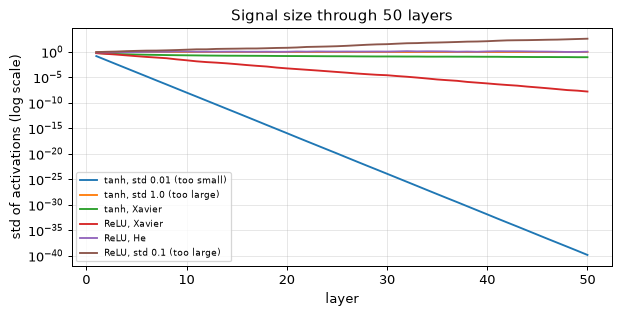

In [18]:
def forward_stds(act, weight_std_fn, n_layers=50, width=256, batch=512):
    h = rng.normal(size=(batch, width)); stds = []
    for _ in range(n_layers):
        W = rng.normal(size=(width, width)) * weight_std_fn(width)
        h = act(h @ W); stds.append(h.std())
    return np.array(stds)

relu = lambda x: np.maximum(0, x)
configs = {
    "tanh, std 0.01 (too small)": (np.tanh, lambda n: 0.01),
    "tanh, std 1.0 (too large)":  (np.tanh, lambda n: 1.0),
    "tanh, Xavier":               (np.tanh, lambda n: np.sqrt(2 / (n + n))),
    "ReLU, Xavier":               (relu,    lambda n: np.sqrt(2 / (n + n))),
    "ReLU, He":                   (relu,    lambda n: np.sqrt(2 / n)),
    "ReLU, std 0.1 (too large)":  (relu,    lambda n: 0.1),
}
plt.figure(figsize=(7, 3.6))
with np.errstate(over="ignore", invalid="ignore"):
    for name, (act, wfn) in configs.items():
        s = forward_stds(act, wfn)
        plt.semilogy(np.arange(1, 51), s, label=name)
        print(f"{name:28s} activation std after layer 1: {s[0]:.2e}   after layer 50: {s[-1]:.2e}")
plt.xlabel("layer"); plt.ylabel("std of activations (log scale)"); plt.legend(fontsize=7)
plt.title("Signal size through 50 layers"); plt.tight_layout(); plt.show()

**Reading the plot.** Too-small weights make activations vanish exponentially; too-large ones saturate tanh (std stuck near 1, derivatives near 0) or explode ReLU. ReLU with Xavier halves the variance each layer ($2^{-50}$ overall), while He keeps it flat. Tanh with Xavier decays slowly because tanh shrinks values a little.

**Orthogonal initialisation.** Take the Q factor of a QR decomposition of a random Gaussian matrix. Since $Q^\top Q = I$, the layer keeps the length of any input: $\lVert Qx\rVert = \lVert x\rVert$. Through 50 purely linear layers the signal neither grows nor shrinks.

In [19]:
def orthogonal(n):
    Q, R = np.linalg.qr(rng.normal(size=(n, n)))
    return Q * np.sign(np.diag(R))          # sign fix makes the distribution uniform over rotations

x0 = rng.normal(size=256)
h_orth, h_gauss = x0.copy(), x0.copy()
for _ in range(50):
    h_orth = orthogonal(256) @ h_orth
    h_gauss = (rng.normal(size=(256, 256)) / np.sqrt(256)) @ h_gauss    # same variance, not orthogonal
print(f"||x|| = {np.linalg.norm(x0):.3f}")
print(f"after 50 orthogonal linear layers: {np.linalg.norm(h_orth):.3f}   after 50 Gaussian (1/n variance) layers: {np.linalg.norm(h_gauss):.3f}")
W = torch.empty(4, 4); nn.init.orthogonal_(W)
print("torch nn.init.orthogonal_: W^T W == I ?", torch.allclose(W.T @ W, torch.eye(4), atol=1e-5))

||x|| = 15.945
after 50 orthogonal linear layers: 15.945   after 50 Gaussian (1/n variance) layers: 13.204
torch nn.init.orthogonal_: W^T W == I ? True


## 6. Optimisers from scratch

**What it is.** An **optimiser** is the rule that turns gradients into weight updates. All of them start from gradient descent and add memory (momentum) and/or per-weight step sizes (adaptivity). A longer tour with PyTorch usage is in [02 optimizers](02_optimizers.ipynb); the convex-optimisation theory is in [14/06 optimization](../14_Mathematics/06_optimization.ipynb).

**Simple analogy.** Walking downhill in fog. SGD looks at the slope under your feet and takes a step. Momentum is a ball that builds up speed in a consistent direction. Adaptive methods (AdaGrad, RMSProp, Adam) give each direction its own step size: short steps where the ground is steep and bumpy, long steps where it is flat.

Notation: $\theta$ parameters, $g_t = \nabla L(\theta_t)$ the gradient, $\eta$ the learning rate, $\epsilon \approx 10^{-8}$ a tiny number to avoid dividing by zero. Squares and square roots are per element.

| Optimiser | Update rule | In words |
|---|---|---|
| **SGD** | $\theta \leftarrow \theta - \eta g_t$ | step against the gradient |
| **Momentum** | $m \leftarrow \beta m + g_t;\ \theta \leftarrow \theta - \eta m$ | keep a running sum of past gradients ($\beta \approx 0.9$) |
| **Nesterov** | $m \leftarrow \beta m + \nabla L(\theta - \eta\beta m);\ \theta \leftarrow \theta - \eta m$ | look ahead to where momentum is taking you, then correct |
| **AdaGrad** | $v \leftarrow v + g_t^2;\ \theta \leftarrow \theta - \eta\, g_t/(\sqrt{v}+\epsilon)$ | divide by the total gradient size so far (step size only ever shrinks) |
| **RMSProp** | $v \leftarrow \rho v + (1-\rho) g_t^2;\ \theta \leftarrow \theta - \eta\, g_t/(\sqrt{v}+\epsilon)$ | like AdaGrad but forgets old gradients |
| **Adam** | $m \leftarrow \beta_1 m + (1-\beta_1) g_t$; $v \leftarrow \beta_2 v + (1-\beta_2) g_t^2$; $\hat m = m/(1-\beta_1^t)$, $\hat v = v/(1-\beta_2^t)$; $\theta \leftarrow \theta - \eta\,\hat m/(\sqrt{\hat v}+\epsilon)$ | momentum + RMSProp + **bias correction** |
| **AdamW** | Adam step, then $\theta \leftarrow \theta - \eta\lambda\theta$ | weight decay applied **directly**, not through the gradient |

**Bias correction.** $m$ and $v$ start at zero, so early on they are too small (biased towards zero). Dividing by $1-\beta^t$ fixes that: at $t=1$, $\hat m = g_1$ exactly. Without it, Adam's first steps are distorted.

**Decoupled weight decay (AdamW).** "L2 regularisation" adds $\lambda\theta$ to the gradient. In SGD that is the same as shrinking the weights, but in Adam the extra term is then divided by $\sqrt{\hat v}$, so weights with large gradients are barely regularised. AdamW (Loshchilov and Hutter) applies the shrink $\eta\lambda\theta$ separately, so every weight decays at the same relative rate. AdamW is the default optimiser for transformers.

Below, each optimiser runs 300 steps on the **Rosenbrock-style** function $f(x,y) = (1-x)^2 + 10(y-x^2)^2$, a curved valley with its minimum at $(1, 1)$. Learning rates were hand-picked per optimiser (illustrative, not a fair benchmark).

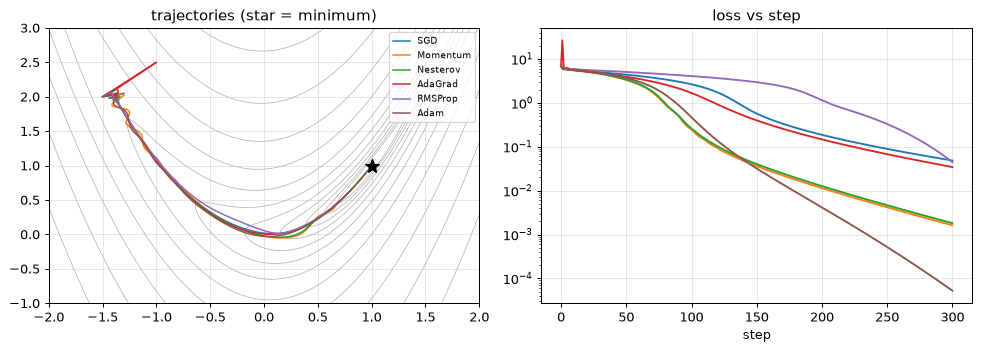

SGD       lr=0.01   final loss 4.85e-02  at [0.782  0.6015]
Momentum  lr=0.002  final loss 1.62e-03  at [0.9601 0.9201]
Nesterov  lr=0.002  final loss 1.81e-03  at [0.9578 0.9156]
AdaGrad   lr=0.5    final loss 3.45e-02  at [0.8156 0.6585]
RMSProp   lr=0.01   final loss 4.45e-02  at [0.7903 0.617 ]
Adam      lr=0.05   final loss 5.24e-05  at [0.9928 0.9854]


In [20]:
def rosen(p):  x, y = p; return (1 - x) ** 2 + 10 * (y - x ** 2) ** 2
def rosen_grad(p):
    x, y = p; return np.array([-2 * (1 - x) - 40 * x * (y - x ** 2), 20 * (y - x ** 2)])

def optimise(name, lr, steps=300, beta=0.9, b1=0.9, b2=0.999, rho=0.9, eps=1e-8, wd=0.0, start=(-1.5, 2.0)):
    p = np.array(start, dtype=float); m = np.zeros(2); v = np.zeros(2); path = [p.copy()]
    for t in range(1, steps + 1):
        g = rosen_grad(p - lr * beta * m) if name == "Nesterov" else rosen_grad(p)
        if name == "SGD":
            p = p - lr * g
        elif name in ("Momentum", "Nesterov"):
            m = beta * m + g; p = p - lr * m
        elif name == "AdaGrad":
            v = v + g ** 2; p = p - lr * g / (np.sqrt(v) + eps)
        elif name == "RMSProp":
            v = rho * v + (1 - rho) * g ** 2; p = p - lr * g / (np.sqrt(v) + eps)
        elif name in ("Adam", "AdamW"):
            m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * g ** 2
            m_hat = m / (1 - b1 ** t); v_hat = v / (1 - b2 ** t)          # bias correction
            p = p - lr * m_hat / (np.sqrt(v_hat) + eps)
            if name == "AdamW": p = p - lr * wd * p                       # decoupled weight decay
        path.append(p.copy())
    return np.array(path)

settings = {"SGD": 0.01, "Momentum": 0.002, "Nesterov": 0.002, "AdaGrad": 0.5, "RMSProp": 0.01, "Adam": 0.05}
paths = {name: optimise(name, lr) for name, lr in settings.items()}

xx, yy = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-1, 3, 200))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].contour(xx, yy, rosen((xx, yy)), levels=np.logspace(-1, 3, 15), colors="0.7", linewidths=0.6)
for name, P in paths.items():
    ax[0].plot(P[:, 0], P[:, 1], lw=1.2, label=name)
    ax[1].semilogy([rosen(p) + 1e-12 for p in P], label=name)
ax[0].plot(1, 1, "k*", ms=12); ax[0].set_title("trajectories (star = minimum)"); ax[0].legend(fontsize=7)
ax[1].set_title("loss vs step"); ax[1].set_xlabel("step"); plt.tight_layout(); plt.show()
for name, P in paths.items(): print(f"{name:9s} lr={settings[name]:<6} final loss {rosen(P[-1]):.2e}  at {P[-1]}")

**Check: our Adam equals `torch.optim.Adam`.** Writing the update yourself is the best way to understand it; checking it against the library is the best way to trust it.

In [21]:
p_t = torch.tensor([-1.5, 2.0], dtype=torch.float64, requires_grad=True)
opt = torch.optim.Adam([p_t], lr=0.05)
for _ in range(300):
    opt.zero_grad()
    x_, y_ = p_t
    ((1 - x_) ** 2 + 10 * (y_ - x_ ** 2) ** 2).backward()
    opt.step()
print("ours :", paths["Adam"][-1]); print("torch:", p_t.detach().numpy())

# Adam + L2 vs AdamW: two weights of equal size, one with large gradients and one with small
def decay_demo(decoupled, seed, steps=200, lr=0.01, lam=0.1):
    r_ = np.random.default_rng(seed)
    theta = np.array([1.0, 1.0]); m = np.zeros(2); v = np.zeros(2); b1, b2 = 0.9, 0.999
    for t in range(1, steps + 1):
        g = np.array([10.0, 0.01]) * r_.normal(size=2)            # zero-mean noisy gradients, very different scales
        if not decoupled: g = g + lam * theta                       # L2 regularisation goes through Adam's scaling
        m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * g ** 2
        theta = theta - lr * (m / (1 - b1 ** t)) / (np.sqrt(v / (1 - b2 ** t)) + 1e-8)
        if decoupled: theta = theta - lr * lam * theta              # AdamW
    return theta
print("\nweights after 200 steps, both started at 1.0 (gradient scales [10, 0.01]); average of 30 runs")
print("  Adam + L2 :", np.mean([decay_demo(False, s) for s in range(30)], axis=0), "<- decay depends on the gradient scale")
print("  AdamW     :", np.mean([decay_demo(True, s) for s in range(30)], axis=0),
      f"<- same shrink for both, (1 - lr*lam)^200 = {(1 - 0.001) ** 200:.3f}")

ours : [0.9928 0.9854]
torch: [0.9928 0.9854]

weights after 200 steps, both started at 1.0 (gradient scales [10, 0.01]); average of 30 runs
  Adam + L2 : [1.032  0.0172] <- decay depends on the gradient scale
  AdamW     : [0.8657 0.8285] <- same shrink for both, (1 - lr*lam)^200 = 0.819


### 6.1 Newer and second-order optimisers (brief)

| Optimiser | Idea in one line | Formula sketch | Why people use it |
|---|---|---|---|
| **Lion** (Chen et al., 2023) | only the **sign** of a momentum blend is used, so every weight moves by exactly $\pm\eta$ | $\theta \leftarrow \theta - \eta\,\operatorname{sign}(\beta_1 m + (1-\beta_1)g)$, then update $m$ | one state buffer instead of two (less memory); needs a smaller LR than AdamW |
| **Adafactor** (Shazeer and Stern, 2018) | store the second moment of an $n\times m$ matrix as a row vector and a column vector | $\hat V \approx R\,C^\top / (\mathbf{1}^\top R)$ | memory $O(n+m)$ instead of $O(nm)$; used for T5 |
| **Muon** (Jordan et al., 2024, blog post) | for 2D weight matrices, replace the momentum matrix by its nearest **orthogonal** matrix (all singular values set to 1) via a few Newton-Schulz iterations | $\theta \leftarrow \theta - \eta\,\text{Orth}(M)$ | strong results in speed-run training of small transformers (as of late 2026 still being evaluated at large scale) |
| **Shampoo** (Gupta et al., 2018) | precondition a matrix gradient from both sides with accumulated statistics | $L \mathrel{+}= GG^\top$, $R \mathrel{+}= G^\top G$, step $L^{-1/4} G R^{-1/4}$ | approximates full-matrix AdaGrad; a distributed variant won a large optimiser benchmark |
| **Newton's method** | use curvature (the **Hessian** $H$, the matrix of second derivatives) | $\theta \leftarrow \theta - H^{-1} g$ | converges in very few steps near a minimum, but $H$ is $P\times P$: impossible for millions of weights |
| **L-BFGS** | build a cheap Hessian-inverse approximation from the last ~10 gradient differences | quasi-Newton two-loop recursion | excellent for small, smooth, full-batch problems (`torch.optim.LBFGS`); poor with noisy mini-batches |

In [22]:
# Muon's core step: orthogonalise a matrix with a Newton-Schulz iteration (simple cubic version)
def newton_schulz_orth(M, steps=10):
    X = M / np.linalg.norm(M)                     # scale so all singular values are <= 1
    for _ in range(steps):
        X = 1.5 * X - 0.5 * X @ X.T @ X           # pushes every singular value towards 1
    return X
M = rng.normal(size=(6, 4))
print("singular values before:", np.linalg.svd(M, compute_uv=False))
print("singular values after :", np.linalg.svd(newton_schulz_orth(M), compute_uv=False))

# Newton on a quadratic: one step lands exactly on the minimum
A = np.array([[10.0, 2.0], [2.0, 1.0]]); bq = np.array([1.0, -1.0])     # f = 0.5 x^T A x - b^T x, Hessian = A
x_n = np.array([5.0, 5.0]); x_n = x_n - np.linalg.solve(A, A @ x_n - bq)
print("\nNewton after 1 step:", x_n, " exact minimum:", np.linalg.solve(A, bq))

# L-BFGS on the Rosenbrock function
p_l = torch.tensor([-1.5, 2.0], dtype=torch.float64, requires_grad=True)
lbfgs = torch.optim.LBFGS([p_l], lr=1, max_iter=100, line_search_fn="strong_wolfe")
def closure():
    lbfgs.zero_grad(); loss = (1 - p_l[0]) ** 2 + 10 * (p_l[1] - p_l[0] ** 2) ** 2; loss.backward(); return loss
lbfgs.step(closure)
print("L-BFGS result:", p_l.detach().numpy(), " function evaluations:", lbfgs.state[p_l]["func_evals"])

singular values before: [3.68   3.2548 2.7978 1.7101]
singular values after : [1. 1. 1. 1.]

Newton after 1 step: [ 0.5 -2. ]  exact minimum: [ 0.5 -2. ]
L-BFGS result: [1. 1.]  function evaluations: 28


## 7. The learning rate

**What it is.** The **learning rate** $\eta$ is the step size: how far the weights move per update. It is usually the single most important hyperparameter (a setting you choose rather than learn).

### 7.1 Too high vs too low

**The maths on the simplest case.** For $f(w) = \tfrac{a}{2}w^2$ (curvature $a$), gradient descent gives $w_{t+1} = w_t - \eta a w_t = (1-\eta a)\,w_t$. So:
- $0 < \eta < 1/a$: smooth, monotone convergence (too small means slow);
- $1/a < \eta < 2/a$: converges while oscillating around the minimum;
- $\eta > 2/a$: $|1-\eta a| > 1$, so $w$ grows every step: **divergence**.

In a real network, $a$ is the largest curvature direction (the top eigenvalue of the Hessian, often called the **sharpness**), so the stable learning rate is limited by the sharpest direction.

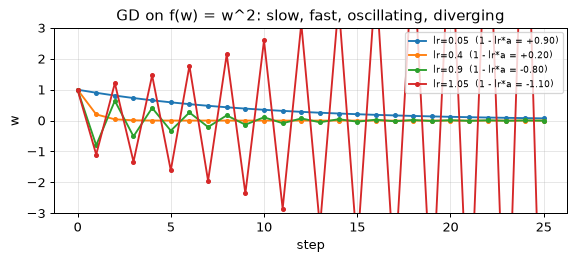

In [23]:
a_curv = 2.0                                      # f(w) = w^2, so the curvature a = 2 and divergence starts at lr > 1
fig, ax = plt.subplots(figsize=(6.5, 3))
for lr in [0.05, 0.4, 0.9, 1.05]:
    w = 1.0; ws = [w]
    for _ in range(25): w = w - lr * a_curv * w; ws.append(w)
    ax.plot(ws, marker=".", label=f"lr={lr}  (1 - lr*a = {1 - lr * a_curv:+.2f})")
ax.set_ylim(-3, 3); ax.set_xlabel("step"); ax.set_ylabel("w"); ax.legend(fontsize=7)
ax.set_title("GD on f(w) = w^2: slow, fast, oscillating, diverging"); plt.tight_layout(); plt.show()

### 7.2 The LR range test (learning-rate finder)

**What it is.** A quick experiment (Leslie Smith, 2015) to pick a learning rate before real training: start with a tiny LR and multiply it by a constant factor every mini-batch for a few hundred steps, recording the loss. The loss first barely moves, then falls quickly, then explodes.

**How to read it.** Pick an LR somewhat below the point where the loss is lowest, typically where the curve is **steepest downward**, or about one tenth of the LR at the minimum. It is a heuristic, not a guarantee.

$$\eta_k = \eta_\text{min}\left(\frac{\eta_\text{max}}{\eta_\text{min}}\right)^{k/(K-1)}, \quad k = 0,\dots,K-1$$

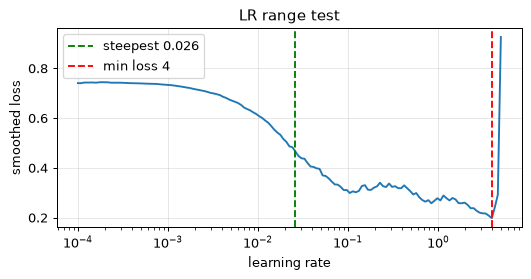

suggestions: steepest-descent LR = 0.0261, min-loss LR / 10 = 0.396


In [24]:
from sklearn.datasets import make_moons
Xm, ym = make_moons(n_samples=2000, noise=0.2, random_state=0)
Xm_t, ym_t = torch.tensor(Xm, dtype=torch.float32), torch.tensor(ym)

def make_mlp(seed=0, width=64):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(2, width), nn.ReLU(), nn.Linear(width, width), nn.ReLU(), nn.Linear(width, 2))

def lr_range_test(lr_min=1e-4, lr_max=10, steps=150, batch=64, smooth=0.9):
    model = make_mlp(); opt = torch.optim.SGD(model.parameters(), lr=lr_min, momentum=0.9)
    lrs = lr_min * (lr_max / lr_min) ** (np.arange(steps) / (steps - 1))
    g = torch.Generator().manual_seed(0); losses, avg = [], 0.0
    for k, lr in enumerate(lrs):
        for group in opt.param_groups: group["lr"] = lr
        idx = torch.randint(0, len(Xm_t), (batch,), generator=g)
        loss = F.cross_entropy(model(Xm_t[idx]), ym_t[idx])
        opt.zero_grad(); loss.backward(); opt.step()
        avg = smooth * avg + (1 - smooth) * loss.item()   # smoothed loss
        losses.append(avg / (1 - smooth ** (k + 1)))                                     # bias-corrected EMA
        if not math.isfinite(avg) or avg > 4 * min(losses): break                          # stop once it explodes
    return lrs[:len(losses)], np.array(losses)

lrs_f, losses_f = lr_range_test()
i_min = np.argmin(losses_f)
i_steep = np.argmin(np.gradient(losses_f[:i_min + 1], np.log(lrs_f[:i_min + 1])))
plt.semilogx(lrs_f, losses_f); plt.axvline(lrs_f[i_steep], ls="--", c="g", label=f"steepest {lrs_f[i_steep]:.2g}")
plt.axvline(lrs_f[i_min], ls="--", c="r", label=f"min loss {lrs_f[i_min]:.2g}")
plt.xlabel("learning rate"); plt.ylabel("smoothed loss"); plt.legend(); plt.title("LR range test"); plt.tight_layout(); plt.show()
print(f"suggestions: steepest-descent LR = {lrs_f[i_steep]:.3g}, min-loss LR / 10 = {lrs_f[i_min] / 10:.3g}")

### 7.3 Learning-rate schedules

**What it is.** A **schedule** changes the learning rate during training. Large steps early make fast progress; small steps late let the model settle into a good minimum instead of bouncing around it. **Warmup** (starting from a very small LR and increasing it linearly) protects the first steps, when Adam's statistics are unreliable and the weights are random.

$T$ = total steps, $t$ = current step, $T_w$ = warmup steps, $\eta_\text{max}$ = peak LR.

| Schedule | Formula | Typical use |
|---|---|---|
| Step decay | $\eta_\text{max}\,\gamma^{\lfloor t/s\rfloor}$ (e.g. $\gamma=0.1$ every $s$ steps) | classic ResNet training |
| Exponential | $\eta_\text{max}\,\gamma^{t}$ | simple smooth decay |
| Cosine | $\eta_\text{min} + \tfrac12(\eta_\text{max}-\eta_\text{min})\big(1+\cos(\pi t/T)\big)$ | very common default |
| Warmup + cosine | linear $0\to\eta_\text{max}$ over $T_w$, then cosine | transformers / LLM pre-training |
| One-cycle (Smith and Topin) | cosine up from $\eta_\text{max}/25$ to $\eta_\text{max}$ over about 30% of steps, then cosine down to about $\eta_\text{max}/(25\cdot 10^4)$ | fast training of CNNs ("super-convergence") |
| Inverse square root | $\eta_\text{max}\,\min\!\big(t/T_w,\ \sqrt{T_w/t}\big)$ | original Transformer paper |
| WSD (warmup-stable-decay) | warmup, then **constant**, then a short fast decay (e.g. last 10-20%) | LLM pre-training when you do not know $T$ in advance; you can branch off and decay from any checkpoint |

In PyTorch: `torch.optim.lr_scheduler` has `StepLR`, `ExponentialLR`, `CosineAnnealingLR`, `OneCycleLR`, and `LambdaLR` (any formula you write). Call `scheduler.step()` once per step (or per epoch, depending on how you defined it).

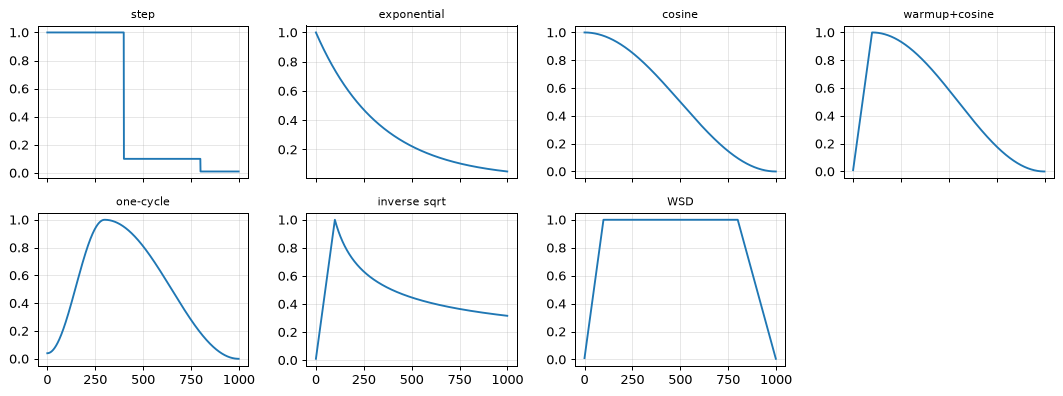

max |ours - torch OneCycleLR| = 0.00e+00


In [25]:
T_total, T_warm, lr_peak = 1000, 100, 1.0
def step_decay(t):  return lr_peak * 0.1 ** (t // 400)
def expo(t):        return lr_peak * 0.997 ** t
def cosine(t, lr_min=0.0): return lr_min + 0.5 * (lr_peak - lr_min) * (1 + math.cos(math.pi * t / T_total))
def warmup_cosine(t):
    if t < T_warm: return lr_peak * (t + 1) / T_warm
    return 0.5 * lr_peak * (1 + math.cos(math.pi * (t - T_warm) / (T_total - T_warm)))
def one_cycle(t, pct=0.3, div=25, final_div=1e4):     # same conventions as torch's OneCycleLR
    start, low = lr_peak / div, lr_peak / div / final_div
    up = pct * T_total - 1                                 # step at which the peak is reached
    cos_interp = lambda a, b, frac: b + (a - b) * 0.5 * (1 + math.cos(math.pi * frac))
    if t <= up: return cos_interp(start, lr_peak, t / up)
    return cos_interp(lr_peak, low, (t - up) / (T_total - 1 - up))
def inv_sqrt(t):    return lr_peak * min((t + 1) / T_warm, math.sqrt(T_warm / (t + 1)))
def wsd(t, decay_frac=0.2):
    t_decay = int((1 - decay_frac) * T_total)
    if t < T_warm: return lr_peak * (t + 1) / T_warm
    if t < t_decay: return lr_peak
    return lr_peak * (1 - (t - t_decay) / (T_total - t_decay))

schedules = {"step": step_decay, "exponential": expo, "cosine": cosine, "warmup+cosine": warmup_cosine,
             "one-cycle": one_cycle, "inverse sqrt": inv_sqrt, "WSD": wsd}
fig, axes = plt.subplots(2, 4, figsize=(12, 4.5), sharex=True)
for axx, (name, fn) in zip(axes.flat, schedules.items()):
    axx.plot([fn(t) for t in range(T_total)]); axx.set_title(name, fontsize=9)
axes.flat[-1].axis("off"); plt.tight_layout(); plt.show()

# Our one-cycle matches torch's OneCycleLR (cosine annealing, default settings)
opt_ = torch.optim.SGD([nn.Parameter(torch.zeros(1))], lr=lr_peak)
sched = torch.optim.lr_scheduler.OneCycleLR(opt_, max_lr=lr_peak, total_steps=T_total, cycle_momentum=False)
torch_lrs = []
for t in range(T_total):
    torch_lrs.append(sched.get_last_lr()[0]); opt_.step(); sched.step()
print("max |ours - torch OneCycleLR| =", f"{max(abs(one_cycle(t) - torch_lrs[t]) for t in range(T_total)):.2e}")

### 7.4 Batch size and learning rate: the linear scaling rule

**The idea.** One SGD step on a batch of $kB$ examples averages $k$ times more gradients. Compare it with $k$ small steps of size $\eta$ on batches of $B$: if the weights hardly change during those $k$ steps, the $k$ small steps add up to $\eta \sum_{j} g_j = k\eta \cdot \bar g$. So a single big-batch step needs learning rate $k\eta$ to make the same progress:

$$B \to kB \quad\Rightarrow\quad \eta \to k\,\eta \qquad \text{(Goyal et al., 2017, for SGD; with warmup)}$$

The rule breaks down for very large batches (beyond what is called the **critical batch size**, more data per step stops helping) and when the LR becomes too large for stability. For Adam-type optimisers, a **square-root rule** $\eta \to \sqrt{k}\,\eta$ is often a better starting point. Treat both as starting points for tuning, not laws.

In [26]:
# Linear regression: compare k=8 SGD steps (batch 16, lr) with 1 step (batch 128, 8*lr) from the same start
Xl = rng.normal(size=(128, 10)); yl = Xl @ rng.normal(size=10) + 0.1 * rng.normal(size=128)
def grad_lin(w, idx): Xi, yi = Xl[idx], yl[idx]; return 2 * Xi.T @ (Xi @ w - yi) / len(idx)
w0 = np.zeros(10); lr_small = 0.002
w_small = w0.copy()
for j in range(8): w_small -= lr_small * grad_lin(w_small, np.arange(16 * j, 16 * (j + 1)))
w_big = w0 - 8 * lr_small * grad_lin(w0, np.arange(128))
w_big_same_lr = w0 - lr_small * grad_lin(w0, np.arange(128))
print(f"distance moved: 8 small steps {np.linalg.norm(w_small - w0):.4f} | 1 big step, lr x8 {np.linalg.norm(w_big - w0):.4f}"
      f" | 1 big step, same lr {np.linalg.norm(w_big_same_lr - w0):.4f}")
print(f"difference between the two scaled updates: {np.linalg.norm(w_small - w_big):.4f} (small because lr is small)")

distance moved: 8 small steps 0.0854 | 1 big step, lr x8 0.0867 | 1 big step, same lr 0.0108
difference between the two scaled updates: 0.0014 (small because lr is small)


### 7.5 Per-parameter-group learning rates

An optimiser can hold several **parameter groups**, each with its own LR and weight decay. Two very common uses:
1. **No weight decay on biases and normalisation weights** (shrinking a LayerNorm gain towards 0 does not regularise anything useful).
2. **Discriminative fine-tuning:** a smaller LR for a pretrained backbone than for a newly added head, so the pretrained features are not destroyed.

In [27]:
net = nn.Sequential(nn.Linear(16, 32), nn.LayerNorm(32), nn.ReLU(), nn.Linear(32, 4))
backbone, head = net[:3], net[3]
decay, no_decay = [], []
for n_, p_ in backbone.named_parameters():
    (no_decay if p_.ndim == 1 else decay).append(p_)         # 1-D tensors = biases and norm gains
opt_groups = torch.optim.AdamW([
    {"params": decay,                "lr": 1e-4, "weight_decay": 0.01},   # pretrained weights: small LR
    {"params": no_decay,             "lr": 1e-4, "weight_decay": 0.0},
    {"params": head.parameters(),    "lr": 1e-3, "weight_decay": 0.01},   # new head: larger LR
])
for i, g_ in enumerate(opt_groups.param_groups):
    print(f"group {i}: {sum(p.numel() for p in g_['params']):5d} params  lr={g_['lr']}  weight_decay={g_['weight_decay']}")

group 0:   512 params  lr=0.0001  weight_decay=0.01
group 1:    96 params  lr=0.0001  weight_decay=0.0
group 2:   132 params  lr=0.001  weight_decay=0.01


## 8. Batches, epochs and gradient noise

**What it is.** The gradient we want is the average over the whole training set, $\nabla L = \frac1N \sum_{i=1}^N \nabla \ell_i$. Computing it exactly every step is expensive, so we estimate it from a **mini-batch** of $B$ random examples.

| Variant | Batch size | Gradient | Pros | Cons |
|---|---|---|---|---|
| Full-batch gradient descent | $N$ | exact | smooth, deterministic | one update per pass over the data; does not fit in memory for big data |
| Mini-batch SGD | typically 32 to a few thousand (LLMs: millions of tokens) | noisy estimate | fast, uses hardware well, noise can help generalisation | needs LR tuning with batch size |
| Stochastic (online) SGD | 1 | very noisy | cheapest step | poor hardware use, very noisy |

**Vocabulary.** An **iteration** (or step) is one update. An **epoch** is one full pass over the training set, so

$$\text{iterations per epoch} = \lceil N / B \rceil$$

**Gradient noise.** If per-example gradients have variance $\sigma^2$, the mini-batch average has variance $\sigma^2 / B$ (for sampling with replacement). Doubling the batch halves the noise variance, so the standard deviation only drops by $\sqrt2$. That is why huge batches give diminishing returns.

In [28]:
N_ = 4096
Xg = rng.normal(size=(N_, 5)); yg = Xg @ rng.normal(size=5) + rng.normal(size=N_)
w_now = np.zeros(5)
per_ex = 2 * Xg * (Xg @ w_now - yg)[:, None]          # per-example gradients of the squared error, shape (N, 5)
full = per_ex.mean(axis=0)
print(f"N = {N_}; iterations per epoch with B=64: {math.ceil(N_ / 64)}")
print(" batch B | mean squared error of the mini-batch gradient | x B (should be ~constant)")
for Bsz in [1, 4, 16, 64, 256, 1024]:
    errs = [np.sum((per_ex[rng.integers(0, N_, Bsz)].mean(0) - full) ** 2) for _ in range(300)]
    print(f"  {Bsz:6d} | {np.mean(errs):10.4f} | {np.mean(errs) * Bsz:8.2f}")

N = 4096; iterations per epoch with B=64: 64
 batch B | mean squared error of the mini-batch gradient | x B (should be ~constant)
       1 |   110.8914 |   110.89
       4 |    38.1998 |   152.80
      16 |     8.6333 |   138.13
      64 |     2.3131 |   148.04
     256 |     0.5201 |   133.15
    1024 |     0.1420 |   145.40


### 8.1 Gradient accumulation

**What it is.** When a big batch does not fit in memory, split it into $k$ **micro-batches**, run forward and backward on each, and let the gradients **add up** in `.grad` (PyTorch accumulates by default). Step the optimiser once after $k$ micro-batches. If each micro-batch loss is divided by $k$, the result equals the big-batch gradient exactly:

$$\nabla \frac{1}{kb}\sum_{i=1}^{kb} \ell_i = \sum_{j=1}^{k} \nabla\Big(\frac1k \cdot \frac1b \sum_{i \in \text{micro-batch } j} \ell_i\Big)$$

**Caveats.** BatchNorm statistics are computed per micro-batch, so they differ from the big batch (LayerNorm and RMSNorm do not have this issue). With variable-length sequences, divide by the total token count across all micro-batches, not by $k$. In data-parallel training, skip the gradient all-reduce on all but the last micro-batch (`no_sync()` in DDP; see [11 distributed training](11_distributed_training.ipynb)).

In [29]:
torch.manual_seed(0)
model_acc = nn.Sequential(nn.Linear(10, 32), nn.GELU(), nn.Linear(32, 3))
Xa, ya = torch.randn(32, 10), torch.randint(0, 3, (32,))

model_acc.zero_grad()
F.cross_entropy(model_acc(Xa), ya).backward()                # one big batch of 32
g_big = [p.grad.clone() for p in model_acc.parameters()]

model_acc.zero_grad(); k = 4
for Xmb, ymb in zip(Xa.chunk(k), ya.chunk(k)):                # 4 micro-batches of 8
    (F.cross_entropy(model_acc(Xmb), ymb) / k).backward()     # grads add up in .grad
g_acc = [p.grad.clone() for p in model_acc.parameters()]
print("accumulated gradient == big-batch gradient:", all(torch.allclose(a, b, atol=1e-6) for a, b in zip(g_big, g_acc)))
print("max difference:", max((a - b).abs().max().item() for a, b in zip(g_big, g_acc)))

accumulated gradient == big-batch gradient: True
max difference: 1.1175870895385742e-08


### 8.2 Shuffling and the data loader

**Why shuffle.** SGD assumes each mini-batch is a fair random sample. If the data is stored sorted (all cats, then all dogs), unshuffled batches each contain one class, and the model swings back and forth towards whichever class it saw last. Re-shuffle every epoch so batches differ between epochs.

**Practical tips.** `DataLoader(dataset, batch_size, shuffle=True)` reshuffles at the start of each epoch. Pass a seeded `torch.Generator` for reproducible orders. `drop_last=True` drops a final short batch (useful with BatchNorm, which misbehaves on tiny batches). Do not shuffle validation or test data; it does not matter for the metric and makes debugging harder.

In [30]:
from torch.utils.data import TensorDataset, DataLoader
ds = TensorDataset(torch.arange(10).float().unsqueeze(1), torch.arange(10))
loader = DataLoader(ds, batch_size=4, shuffle=True, drop_last=False, generator=torch.Generator().manual_seed(0))
for epoch in range(2):
    print(f"epoch {epoch}: batches =", [yb_.tolist() for _, yb_ in loader])
print("iterations per epoch:", len(loader), "(= ceil(10 / 4))")

# Sorted vs shuffled data: logistic regression trained for one epoch with plain SGD
Xs_, ys_ = make_moons(n_samples=1000, noise=0.1, random_state=1)
order = np.argsort(ys_)                                        # sorted by label: all 0s first, then all 1s
for name, idx_order in [("sorted   ", order), ("shuffled ", rng.permutation(1000))]:
    torch.manual_seed(0); clf = nn.Linear(2, 2); opt_s = torch.optim.SGD(clf.parameters(), lr=0.5)
    Xo, yo = torch.tensor(Xs_[idx_order], dtype=torch.float32), torch.tensor(ys_[idx_order])
    for i in range(0, 1000, 20):
        opt_s.zero_grad(); F.cross_entropy(clf(Xo[i:i + 20]), yo[i:i + 20]).backward(); opt_s.step()
    acc = (clf(torch.tensor(Xs_, dtype=torch.float32)).argmax(1).numpy() == ys_).mean()
    print(f"{name} order -> accuracy after one epoch: {acc:.2f}")

epoch 0: batches = [[3, 7, 5, 2], [0, 8, 1, 6], [9, 4]]
epoch 1: batches = [[1, 3, 2, 7], [5, 9, 0, 6], [4, 8]]
iterations per epoch: 3 (= ceil(10 / 4))
sorted    order -> accuracy after one epoch: 0.76
shuffled  order -> accuracy after one epoch: 0.86


## 9. Normalisation layers

**What it is.** A **normalisation layer** rescales activations to roughly zero mean and unit variance, then applies a learnable scale $\gamma$ and shift $\beta$. This keeps the signal in a healthy range throughout training (not only at initialisation), which allows larger learning rates and makes deep networks much easier to train.

**Simple analogy.** Re-centring a microphone level before every stage of a mixing desk, so no stage receives a signal that is too loud or too quiet.

All of them compute $\hat x = (x-\mu)/\sqrt{\sigma^2+\epsilon}$ and $y = \gamma\hat x + \beta$. They differ in **which values** share one $\mu$ and $\sigma^2$. For an activation tensor of shape (batch $B$, channels/features $C$, positions/pixels $S$):

| Layer | Statistics computed over | Formula detail | Typical home |
|---|---|---|---|
| **BatchNorm** | batch (and positions), separately per channel | running averages of $\mu,\sigma^2$ used at eval time | CNNs |
| **LayerNorm** | all features of one example (one token) | same in train and eval | transformers, RNNs |
| **RMSNorm** | all features of one token, **no mean subtraction** | $y = \gamma\, x / \sqrt{\tfrac1d\sum_i x_i^2 + \epsilon}$ | LLaMA-style LLMs |
| **GroupNorm** | groups of channels within one example | LayerNorm on channel groups | detection/segmentation with small batches, diffusion U-Nets |

**BatchNorm train vs eval.** During training, BN uses the current batch's statistics and updates **running estimates** ($\mu_\text{run} \leftarrow (1-m)\mu_\text{run} + m\,\mu_\text{batch}$, $m=0.1$ in PyTorch). In `model.eval()`, it uses the running estimates, so a single example's output does not depend on the rest of the batch. Forgetting `model.eval()` at test time is a classic bug. The full forward and backward derivation of BN is in [18 from scratch, Section 8](18_neural_networks_from_scratch_numpy.ipynb).

In [31]:
torch.manual_seed(0)
x_bn = torch.randn(8, 4) * 3 + 5          # batch of 8, 4 features, mean ~5, std ~3
eps = 1e-5

# BatchNorm (training mode): statistics over the batch, per feature
bn = nn.BatchNorm1d(4)
ours_bn = (x_bn - x_bn.mean(0)) / torch.sqrt(x_bn.var(0, unbiased=False) + eps)
print("BatchNorm  matches torch:", torch.allclose(bn(x_bn), ours_bn, atol=1e-5))
print("  running_mean after 1 batch (0.9*0 + 0.1*batch mean):", bn.running_mean.numpy().round(3))
bn.eval()
print("  eval mode uses running stats -> output mean per feature:", bn(x_bn).mean(0).detach().numpy().round(2), "(not 0)")

# LayerNorm: statistics over the features of each example
ln = nn.LayerNorm(4)
ours_ln = (x_bn - x_bn.mean(1, keepdim=True)) / torch.sqrt(x_bn.var(1, unbiased=False, keepdim=True) + eps)
print("LayerNorm  matches torch:", torch.allclose(ln(x_bn), ours_ln, atol=1e-5))

# RMSNorm: no mean subtraction, divide by the root-mean-square
rms = nn.RMSNorm(4, eps=eps)
ours_rms = x_bn / torch.sqrt((x_bn ** 2).mean(1, keepdim=True) + eps)
print("RMSNorm    matches torch:", torch.allclose(rms(x_bn), ours_rms, atol=1e-5))

# GroupNorm: images (B, C, H, W) with 6 channels split into 2 groups of 3
x_img = torch.randn(2, 6, 5, 5)
gn = nn.GroupNorm(num_groups=2, num_channels=6)
xg_ = x_img.view(2, 2, -1)                                 # (batch, group, everything in the group)
ours_gn = ((xg_ - xg_.mean(-1, keepdim=True)) / torch.sqrt(xg_.var(-1, unbiased=False, keepdim=True) + eps)).view_as(x_img)
print("GroupNorm  matches torch:", torch.allclose(gn(x_img), ours_gn, atol=1e-5))

BatchNorm  matches torch: True
  running_mean after 1 batch (0.9*0 + 0.1*batch mean): [0.558 0.397 0.571 0.481]
  eval mode uses running stats -> output mean per feature: [3.81 2.28 4.66 2.96] (not 0)
LayerNorm  matches torch: True
RMSNorm    matches torch: True
GroupNorm  matches torch: True


### 9.1 Why transformers use LayerNorm / RMSNorm, and pre-norm vs post-norm

**Why not BatchNorm in transformers.** Sequences have different lengths and padding, batches are often small per device, and at generation time you process one token at a time; batch statistics are unreliable or meaningless there. LayerNorm and RMSNorm normalise each token on its own, so behaviour is identical in training and inference. RMSNorm drops the mean and the bias $\beta$, which saves a little compute and works as well in practice, so most recent LLMs use it.

**Where to put the norm.** A transformer block has a residual connection $x + \text{Sublayer}(\cdot)$.

$$\textbf{Post-norm (original Transformer):}\quad x_{l+1} = \text{Norm}\big(x_l + F(x_l)\big)$$
$$\textbf{Pre-norm (GPT-2 onwards):}\quad x_{l+1} = x_l + F\big(\text{Norm}(x_l)\big)$$

In pre-norm, the residual path from input to output is a clean identity (nothing is applied to it), so gradients flow directly to early layers. Pre-norm trains stably with less warmup, which is why it is the default for deep models; post-norm can reach slightly better quality when it does train well (Xiong et al., 2020 analyse this). Pre-norm models need one final norm before the output head.

In [32]:
class PostNormBlock(nn.Module):
    def __init__(self, d): super().__init__(); self.f = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d)); self.norm = nn.LayerNorm(d)
    def forward(self, x): return self.norm(x + self.f(x))

class PreNormBlock(nn.Module):
    def __init__(self, d): super().__init__(); self.f = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d)); self.norm = nn.RMSNorm(d)
    def forward(self, x): return x + self.f(self.norm(x))

torch.manual_seed(0)
x_tok = torch.randn(2, 7, 32)                              # (batch, tokens, features)
for Block in [PostNormBlock, PreNormBlock]:
    stack = nn.Sequential(*[Block(32) for _ in range(12)])
    out = stack(x_tok)
    print(f"{Block.__name__:13s}: output shape {tuple(out.shape)}, output RMS {out.pow(2).mean().sqrt():.2f}"
          + ("  (residual stream grows with depth -> final norm needed)" if Block is PreNormBlock else "  (always re-normalised)"))

PostNormBlock: output shape (2, 7, 32), output RMS 1.00  (always re-normalised)
PreNormBlock : output shape (2, 7, 32), output RMS 1.20  (residual stream grows with depth -> final norm needed)


## 10. Regularisation

**What it is.** **Regularisation** is anything that makes a model generalise better (do well on new data) rather than just fit the training set. **Overfitting** is when training loss keeps falling but validation loss rises: the model memorises noise.

**Simple analogy.** A student who memorises past exam answers (overfitting) vs one who learns the method. Regularisation is the teacher who changes the numbers in practice questions, hides some notes, or stops the cramming session at the right time.

### 10.1 L1 and L2 penalties, and weight decay

$$L_\text{L2} = L + \frac{\lambda}{2}\lVert\theta\rVert_2^2 \;\Rightarrow\; \text{gradient } g + \lambda\theta, \qquad L_\text{L1} = L + \lambda\lVert\theta\rVert_1 \;\Rightarrow\; \text{gradient } g + \lambda\operatorname{sign}(\theta)$$

- **L2** shrinks every weight in proportion to its size: weights get small but rarely exactly zero. With plain SGD, adding $\lambda\theta$ to the gradient is identical to **weight decay** $\theta \leftarrow (1-\eta\lambda)\theta - \eta g$.
- **L1** pushes every weight towards zero by the same amount, so unimportant weights become exactly zero: **sparsity** (built-in feature selection).
- **Weight decay vs L2 in Adam:** not the same; see the AdamW demo in Section 6. Use `AdamW(weight_decay=...)`, typically 0.01-0.1 for transformers, and exclude biases and norm gains (Section 7.5).

In [33]:
# 100 features, only 5 matter. Compare L1 (via soft-thresholding, the exact proximal step) and L2 penalties.
n_s, p_s = 80, 100
Xr = rng.normal(size=(n_s, p_s)); w_true_r = np.zeros(p_s); w_true_r[:5] = [3, -2, 1.5, -1, 2]
yr = Xr @ w_true_r + 0.5 * rng.normal(size=n_s)

def fit(penalty, lam, lr=0.01, steps=3000):
    w = np.zeros(p_s)
    for _ in range(steps):
        g = 2 * Xr.T @ (Xr @ w - yr) / n_s
        if penalty == "L2": w = w - lr * (g + lam * w)
        else:                                                   # L1: gradient step then soft-threshold (ISTA)
            w = w - lr * g; w = np.sign(w) * np.maximum(np.abs(w) - lr * lam, 0)
    return w
for pen, lam in [("L2", 0.5), ("L1", 0.5)]:
    w_ = fit(pen, lam)
    print(f"{pen}: exact zeros {np.sum(w_ == 0):3d}/100 | |w| < 0.05: {np.sum(np.abs(w_) < 0.05):3d} | first 5 weights {w_[:5].round(2)}")

L2: exact zeros   0/100 | |w| < 0.05:  19 | first 5 weights [ 1.54 -1.32  0.78 -0.53  1.02]


L1: exact zeros  95/100 | |w| < 0.05:  95 | first 5 weights [ 2.85 -1.79  1.07 -0.72  1.68]


### 10.2 Dropout (inverted dropout)

**What it is.** During training, **dropout** sets each activation to zero with probability $p$, a different random pattern for every example and step. The network cannot rely on any single unit, which acts like training a large ensemble of thinned networks.

**Inverted dropout** scales the surviving values by $1/(1-p)$ during training, so the expected value is unchanged and **nothing needs to change at test time**:

$$\tilde h = \frac{m \odot h}{1-p}, \quad m_i \sim \text{Bernoulli}(1-p), \qquad \mathbb{E}[\tilde h] = h$$

At eval time dropout is the identity. Typical $p$: 0.1 in transformers (often 0 for large LLM pre-training, which sees each token about once), 0.2-0.5 in MLPs.

In [34]:
def inverted_dropout(h, p, training=True):
    if not training or p == 0: return h                       # eval mode: do nothing
    mask = (rng.random(h.shape) > p)                           # keep with probability 1-p
    return h * mask / (1 - p)                                  # rescale so the expectation is unchanged

h_d = np.ones((10000, 8))
out_d = inverted_dropout(h_d, p=0.3)
print(f"fraction zeroed: {np.mean(out_d == 0):.3f} (target 0.3), mean kept: {out_d.mean():.3f} (target 1.0)")
drop = nn.Dropout(0.3)
t_in = torch.ones(10000, 8)
print(f"torch train mode: zeroed {np.mean(drop(t_in).numpy() == 0):.3f}, survivors scaled to {drop(t_in).max():.4f} = 1/(1-0.3)")
drop.eval(); print("torch eval mode : identity ->", torch.equal(drop(t_in), t_in))

fraction zeroed: 0.299 (target 0.3), mean kept: 1.001 (target 1.0)
torch train mode: zeroed 0.300, survivors scaled to 1.4286 = 1/(1-0.3)
torch eval mode : identity -> True


### 10.3 Early stopping

**What it is.** Watch the validation loss every epoch, keep a copy of the best weights, and stop when it has not improved for `patience` epochs. Then restore the best copy. It is cheap and almost always worth doing. Below, an over-sized MLP fits 30 noisy points; validation loss reaches a minimum and then rises as the model starts to fit the noise.

stopped at epoch 246; best epoch 96 with val MSE 0.0971 (noise floor 0.09)


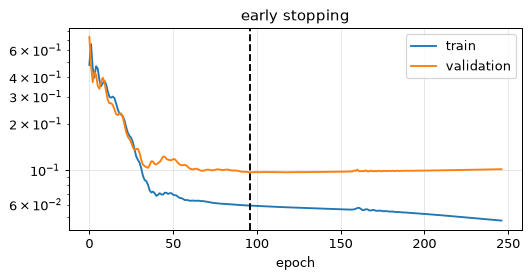

In [35]:
class EarlyStopping:
    def __init__(self, patience=50, min_delta=1e-4):
        self.patience, self.min_delta, self.best, self.bad_epochs, self.best_state = patience, min_delta, float("inf"), 0, None
    def step(self, val_loss, model):                          # returns True when training should stop
        if val_loss < self.best - self.min_delta:
            self.best, self.bad_epochs = val_loss, 0
            self.best_state = copy.deepcopy(model.state_dict())   # remember the best weights
        else:
            self.bad_epochs += 1
        return self.bad_epochs >= self.patience

torch.manual_seed(0)
x_tr = torch.rand(30, 1) * 4 - 2; y_tr = torch.sin(2 * x_tr) + 0.3 * torch.randn(30, 1)
x_va = torch.rand(200, 1) * 4 - 2; y_va = torch.sin(2 * x_va) + 0.3 * torch.randn(200, 1)
big = nn.Sequential(nn.Linear(1, 128), nn.Tanh(), nn.Linear(128, 128), nn.Tanh(), nn.Linear(128, 1))
opt_es = torch.optim.Adam(big.parameters(), lr=3e-3); stopper = EarlyStopping(patience=150)
tr_hist, va_hist = [], []
for epoch in range(2000):
    opt_es.zero_grad(); loss = F.mse_loss(big(x_tr), y_tr); loss.backward(); opt_es.step()
    with torch.no_grad(): v = F.mse_loss(big(x_va), y_va).item()
    tr_hist.append(loss.item()); va_hist.append(v)
    if stopper.step(v, big): break
best_epoch = int(np.argmin(va_hist))
big.load_state_dict(stopper.best_state)                      # restore the best weights
print(f"stopped at epoch {epoch}; best epoch {best_epoch} with val MSE {stopper.best:.4f} (noise floor 0.09)")
plt.semilogy(tr_hist, label="train"); plt.semilogy(va_hist, label="validation"); plt.axvline(best_epoch, ls="--", c="k")
plt.xlabel("epoch"); plt.legend(); plt.title("early stopping"); plt.tight_layout(); plt.show()

### 10.4 Data augmentation, mixup, label smoothing, stochastic depth

**Data augmentation** creates new training examples by changing inputs in ways that do not change the label: flips, crops, colour jitter and rotations for images; noise, time-shifts and SpecAugment masks for audio; back-translation or token masking for text. It encodes prior knowledge ("a flipped cat is still a cat") and is often the strongest regulariser for vision.

**Mixup** (Zhang et al., 2017) blends pairs of examples and their labels:

$$\tilde x = \lambda x_i + (1-\lambda)x_j, \quad \tilde y = \lambda y_i + (1-\lambda)y_j, \quad \lambda \sim \text{Beta}(\alpha, \alpha),\ \alpha \approx 0.2$$

It encourages straight-line behaviour between training examples and improves calibration. **CutMix** pastes a patch of one image into another instead.

**Label smoothing:** see Section 2.3.

**Stochastic depth** (Huang et al., 2016): in a residual network, skip whole residual blocks at random during training, $x_{l+1} = x_l + b\,F(x_l)/(1-p)$ with $b \sim \text{Bernoulli}(1-p)$. It is dropout at the level of layers and is used in vision transformers (often called "drop path").

In [36]:
# Augmentation on a tiny 4x4 "image": horizontal flip, random crop with padding, Gaussian noise
img = np.arange(16, dtype=float).reshape(4, 4)
flipped = img[:, ::-1]
padded = np.pad(img, 1); r0, c0 = rng.integers(0, 3, size=2); cropped = padded[r0:r0 + 4, c0:c0 + 4]
noisy = img + rng.normal(0, 0.5, img.shape)
print("original row 0:", img[0], "| flipped row 0:", flipped[0], "| crop offset:", (int(r0), int(c0)))

def mixup(x, y_onehot, alpha=0.2):
    lam = rng.beta(alpha, alpha); perm = rng.permutation(len(x))
    return lam * x + (1 - lam) * x[perm], lam * y_onehot + (1 - lam) * y_onehot[perm], lam
xm_, ym_oh = rng.normal(size=(4, 3)), np.eye(2)[[0, 1, 0, 1]]
_, y_mixed, lam_ = mixup(xm_, ym_oh)
print(f"mixup lambda = {lam_:.3f}; mixed soft labels:\n{y_mixed}")

class DropPath(nn.Module):                                  # stochastic depth for a residual branch
    def __init__(self, p): super().__init__(); self.p = p
    def forward(self, branch_out):
        if not self.training or self.p == 0: return branch_out
        keep = (torch.rand(branch_out.shape[0], *[1] * (branch_out.ndim - 1)) > self.p).float()   # one coin per example
        return branch_out * keep / (1 - self.p)
dp = DropPath(0.5); print("examples whose branch was kept:", (dp(torch.ones(8, 3))[:, 0] > 0).int().tolist())

original row 0: [0. 1. 2. 3.] | flipped row 0: [3. 2. 1. 0.] | crop offset: (1, 2)
mixup lambda = 0.512; mixed soft labels:
[[1.     0.    ]
 [0.4882 0.5118]
 [0.5118 0.4882]
 [0.     1.    ]]
examples whose branch was kept: [1, 0, 1, 1, 1, 0, 1, 1]


## 11. Training stability

### 11.1 Vanishing and exploding gradients

**What it is.** Backprop multiplies one Jacobian per layer (or per time step in an RNN). A product of many matrices behaves like a power: if its typical gain is below 1 the gradient **vanishes** (early layers stop learning), above 1 it **explodes** (huge updates, NaNs).

**The maths for a linear RNN.** With $h_t = W h_{t-1} + U x_t$,

$$\frac{\partial h_T}{\partial h_0} = W^T \quad (\text{the matrix power}),\qquad \lVert W^T \rVert \approx \rho(W)^T$$

where $\rho(W)$ is the **spectral radius** (largest absolute eigenvalue). With a tanh RNN, each step also multiplies by $\operatorname{diag}(1-h_t^2)$, whose entries are at most 1, so gradients shrink even more (in the plot, the dashed tanh line decays while the linear RNN with the same radius 1.0 stays flat). LSTMs and GRUs fix this with gated, additive memory paths (see [04 RNNs](04_rnn_lstm_gru.ipynb)); transformers avoid long products altogether thanks to attention and residual connections.

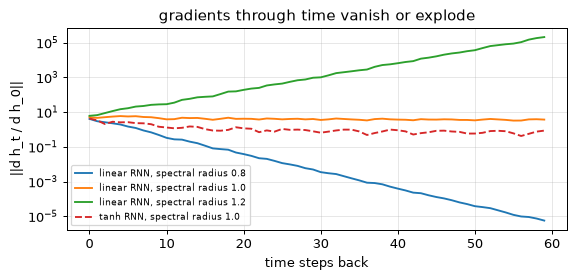

In [37]:
def rnn_grad_norms(radius, T_max=60, d=32, nonlin=None):
    torch.manual_seed(0)
    W = torch.randn(d, d); W = W / torch.linalg.eigvals(W).abs().max() * radius    # set the spectral radius
    h0 = torch.randn(d, requires_grad=True); h = h0; norms = []
    for t in range(1, T_max + 1):
        h = W @ h if nonlin is None else nonlin(W @ h)
        g, = torch.autograd.grad(h.sum(), h0, retain_graph=True)                  # how much h_t depends on h_0
        norms.append(g.norm().item())
    return norms

plt.figure(figsize=(6.5, 3.2))
for radius in [0.8, 1.0, 1.2]:
    plt.semilogy(rnn_grad_norms(radius), label=f"linear RNN, spectral radius {radius}")
plt.semilogy(rnn_grad_norms(1.0, nonlin=torch.tanh), "--", label="tanh RNN, spectral radius 1.0")
plt.xlabel("time steps back"); plt.ylabel("||d h_t / d h_0||"); plt.legend(fontsize=7)
plt.title("gradients through time vanish or explode"); plt.tight_layout(); plt.show()

### 11.2 Gradient clipping by norm

**What it is.** Before the optimiser step, compute the **global gradient norm** over all parameters, $\lVert g\rVert = \sqrt{\sum_i g_i^2}$. If it exceeds a threshold $c$, scale every gradient down by the same factor:

$$g \leftarrow g \cdot \min\Big(1, \frac{c}{\lVert g\rVert}\Big)$$

The direction is kept; only the length is capped. It protects against rare huge gradients (a bad batch, an RNN explosion). Typical $c = 1.0$ for transformers. **Log the pre-clipping norm**: a norm that is clipped on most steps means the LR is too high or something is broken.

(Clipping **by value**, `clip_grad_value_`, clips each element separately and changes the direction; it is rarely preferred.)

In [38]:
def clip_grad_norm(params, max_norm):
    grads = [p.grad for p in params if p.grad is not None]
    total = torch.sqrt(sum((g ** 2).sum() for g in grads))      # one global norm over all parameters
    scale = min(1.0, max_norm / (total.item() + 1e-6))
    for g in grads: g.mul_(scale)
    return total

torch.manual_seed(0)
m1 = nn.Linear(20, 5); m2 = copy.deepcopy(m1)
xc = torch.randn(16, 20) * 50                                    # huge inputs -> huge gradients
for m in (m1, m2): m(xc).pow(2).mean().backward()
before = clip_grad_norm(list(m1.parameters()), max_norm=1.0)
torch_before = torch.nn.utils.clip_grad_norm_(m2.parameters(), max_norm=1.0)
after = torch.sqrt(sum((p.grad ** 2).sum() for p in m1.parameters()))
print(f"norm before {before:.1f} (torch reports {torch_before:.1f}); after clipping {after:.4f}")
print("same clipped gradients as torch:", all(torch.allclose(a.grad, b.grad, atol=1e-6) for a, b in zip(m1.parameters(), m2.parameters())))

norm before 1916.8 (torch reports 1916.8); after clipping 1.0000
same clipped gradients as torch: True


### 11.3 Residual connections

**What it is.** A **residual (skip) connection** adds a block's input to its output: $x_{l+1} = x_l + F(x_l)$. The block only has to learn a *correction* to the identity.

**Why it helps gradient flow.** The Jacobian of one residual block is

$$\frac{\partial x_{l+1}}{\partial x_l} = I + \frac{\partial F}{\partial x_l}$$

so the product over many blocks always contains the identity term: there is a direct path through which the gradient reaches early layers undamped. Without the skip, the Jacobian is just $\partial F/\partial x_l$, and a product of 50 of them can vanish. Residuals (He et al., 2015) are why 100+-layer networks and every transformer train at all.

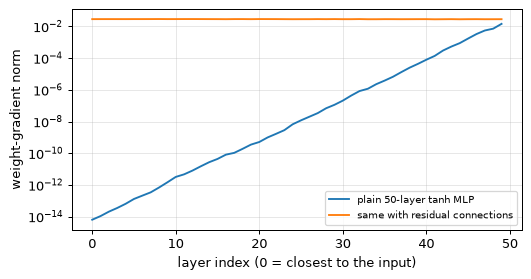

gradient norm at layer 0: plain 6.4e-15  vs residual 2.9e-02


In [39]:
def first_layer_grad(residual, depth=50, width=64, seed=0):
    torch.manual_seed(seed)
    layers = [nn.Linear(width, width) for _ in range(depth)]        # PyTorch default init
    h = torch.randn(128, width)
    for lin in layers:
        h = h + 0.1 * torch.tanh(lin(h)) if residual else torch.tanh(lin(h))
    h.pow(2).mean().backward()
    return [lin.weight.grad.norm().item() for lin in layers]

plain, resid = first_layer_grad(False), first_layer_grad(True)
plt.semilogy(plain, label="plain 50-layer tanh MLP"); plt.semilogy(resid, label="same with residual connections")
plt.xlabel("layer index (0 = closest to the input)"); plt.ylabel("weight-gradient norm"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"gradient norm at layer 0: plain {plain[0]:.1e}  vs residual {resid[0]:.1e}")

### 11.4 Loss spikes and NaN debugging

**Loss spikes** are sudden jumps in the training loss, common in large-scale training. Usual causes and fixes:

| Cause | What you see | Fix |
|---|---|---|
| LR too high for the current sharpness | spikes that grow, gradient norm climbs first | lower peak LR, longer warmup, gradient clipping |
| A bad batch (corrupt or extreme data) | one-off spike at a reproducible step | inspect and filter that data; skip the batch |
| Adam's $v$ too small for a parameter that suddenly gets gradients | spike in rarely-updated embeddings | larger $\epsilon$, lower $\beta_2$ (e.g. 0.95), clipping |
| Attention logits / output logits growing without bound | loss spikes late in training | QK-norm, z-loss, logit soft-capping |
| Low-precision overflow | inf/NaN after a spike | BF16 instead of FP16, loss scaling (Section 12) |

At large scale, a common recovery is to **roll back** to a checkpoint from before the spike and skip the offending batches or lower the LR.

**NaN debugging checklist** (NaN = "not a number", produced by things like $0/0$, $\infty-\infty$, $\log$ of a negative):
1. Find the **first** step where loss or gradients become non-finite (`torch.isfinite`).
2. Check inputs and labels for NaN/inf and label values outside `[0, num_classes)`.
3. Look for unsafe maths: `log(0)`, `sqrt(0)` in backward, division by a std that can be 0, `exp` of a large number. Add $\epsilon$ or use stable built-ins (`log_softmax`, `logsumexp`, `*_with_logits`).
4. Turn on `torch.autograd.set_detect_anomaly(True)` to get the forward operation that created the bad gradient (slow; debug only).
5. Register forward hooks that report the first module whose output is non-finite.
6. Lower the LR, enable clipping, and switch FP16 to BF16 or FP32 to see if the problem disappears.

In [40]:
# A backward NaN: sqrt(x) at x = 0 has an infinite derivative; times 0 gives NaN
x_nan = torch.tensor([0.0, 4.0], requires_grad=True)
(torch.sqrt(x_nan) * torch.tensor([0.0, 1.0])).sum().backward()
print("gradient:", x_nan.grad, "<- NaN appears only in the backward pass")

with torch.autograd.set_detect_anomaly(True):
    x_nan.grad = None
    try:
        (torch.sqrt(x_nan) * torch.tensor([0.0, 1.0])).sum().backward()
    except RuntimeError as e:
        print("anomaly mode says:", str(e).split("\n")[0][:110])

# Forward hooks: report the first module that outputs a non-finite value
model_nan = nn.Sequential(nn.Linear(3, 3), nn.ReLU(), nn.Linear(3, 1))
with torch.no_grad(): model_nan[2].weight[0, 0] = float("inf")       # plant a bug
def make_hook(name):
    def hook(module, inp, out):
        if not torch.isfinite(out).all(): print(f"  non-finite output first seen in module '{name}' ({module.__class__.__name__})")
    return hook
handles = [m.register_forward_hook(make_hook(n)) for n, m in model_nan.named_children()]
_ = model_nan(torch.randn(4, 3) + 1.0)
for h_ in handles: h_.remove()

gradient: tensor([   nan, 0.2500]) <- NaN appears only in the backward pass
anomaly mode says: Function 'SqrtBackward0' returned nan values in its 0th output.
  non-finite output first seen in module '2' (Linear)


## 12. Numerics and efficiency

### 12.1 Number formats: FP32, FP16, BF16, FP8

**What it is.** A floating-point number is stored as a **sign**, an **exponent** (sets the range: how big or small it can be) and a **mantissa** (sets the precision: how many significant digits). Fewer bits means less memory and faster maths, but less range and/or precision.

$$x = (-1)^{s} \times 1.m \times 2^{e - \text{bias}}$$

The table below is computed live from `torch.finfo`. "eps" is the gap between 1 and the next representable number (relative precision); "smallest normal" is the smallest number stored at full precision (smaller ones lose precision, then become 0, which is **underflow**); "max" is the point above which numbers become infinity (**overflow**).

In [41]:
import pandas as pd
formats = [("FP32", torch.float32, "1/8/23"), ("FP16", torch.float16, "1/5/10"), ("BF16", torch.bfloat16, "1/8/7"),
           ("FP8 E4M3", torch.float8_e4m3fn, "1/4/3"), ("FP8 E5M2", torch.float8_e5m2, "1/5/2")]
rows = []
for name, dt, bits in formats:
    fi = torch.finfo(dt)
    rows.append({"format": name, "bits (sign/exp/mantissa)": bits, "bytes": fi.bits // 8,
                 "max": f"{fi.max:.3g}", "smallest normal": f"{fi.smallest_normal:.3g}", "eps": f"{fi.eps:.3g}"})
print(pd.DataFrame(rows).to_string(index=False))

  format bits (sign/exp/mantissa)  bytes      max smallest normal      eps
    FP32                   1/8/23      4  3.4e+38        1.18e-38 1.19e-07
    FP16                   1/5/10      2 6.55e+04         6.1e-05 0.000977
    BF16                    1/8/7      2 3.39e+38        1.18e-38  0.00781
FP8 E4M3                    1/4/3      1      448          0.0156    0.125
FP8 E5M2                    1/5/2      1 5.73e+04         6.1e-05     0.25


**How to read it.** BF16 has the **same range as FP32** (8 exponent bits) but only about 3 significant decimal digits. FP16 has more precision but a tiny range (max 65504), so gradients can underflow and activations can overflow. That is why BF16 is the default for training on modern hardware, and why FP16 training needs **loss scaling**. FP8 comes in two flavours: E4M3 (more precision, used for weights and activations) and E5M2 (more range, used for gradients); FP8 training needs per-tensor scaling factors. Integer formats for inference (INT8, INT4) are covered in [13 quantization](13_quantization_and_compression_advanced.ipynb).

In [42]:
f16 = np.float16
with np.errstate(over="ignore"):
    print("overflow   : float16(70000)              =", f16(70000.0))
print("underflow  : float16(1e-8)               =", f16(1e-8), " (smallest positive float16 is about", f16(2.0 ** -24), ")")
print("precision  : float16(2048) + float16(1)  =", f16(2048) + f16(1), " (the gap between float16 numbers near 2048 is 2)")
acc16, acc32 = f16(0), np.float32(0)
for _ in range(10000): acc16 = f16(acc16 + f16(1e-4)); acc32 += np.float32(1e-4)
print(f"summing 1e-4 ten thousand times: float16 -> {acc16}  float32 -> {acc32:.4f}  (true value 1.0)")
print("BF16 keeps the range but rounds: torch.tensor(1.001, dtype=bfloat16) =", torch.tensor(1.001, dtype=torch.bfloat16).item())

overflow   : float16(70000)              = inf
underflow  : float16(1e-8)               = 0.0  (smallest positive float16 is about 6e-08 )
precision  : float16(2048) + float16(1)  = 2.048e+03  (the gap between float16 numbers near 2048 is 2)
summing 1e-4 ten thousand times: float16 -> 0.25  float32 -> 1.0001  (true value 1.0)
BF16 keeps the range but rounds: torch.tensor(1.001, dtype=bfloat16) = 1.0


### 12.2 Mixed-precision training and loss scaling

**What it is.** **Mixed precision** runs most of the maths (matrix multiplies, convolutions) in 16-bit, while keeping numerically sensitive parts in FP32: a **master copy** of the weights, the optimiser states, reductions such as sums in softmax and norms, and the loss. You get roughly 2x less activation memory and much faster matmuls on hardware with 16-bit units, with almost no accuracy loss.

**Loss scaling** (needed for FP16, not for BF16). Many gradients are smaller than FP16's smallest number and would become 0. Multiply the loss by a scale $S$ (e.g. $2^{16}$) before backward: by the chain rule every gradient is multiplied by $S$ too and moves into FP16's range. Divide the gradients by $S$ (in FP32) before the optimiser step. **Dynamic loss scaling** lowers $S$ whenever an inf/NaN appears (and skips that step) and slowly raises it otherwise.

$$\nabla_\theta (S \cdot L) = S \cdot \nabla_\theta L \quad\Rightarrow\quad g = \frac{1}{S}\,\nabla_\theta(S\cdot L)$$

In PyTorch: wrap the forward pass and loss in `torch.autocast(device_type, dtype=...)`, and for FP16 use `torch.amp.GradScaler`:

```python
scaler = torch.amp.GradScaler("cuda")
with torch.autocast("cuda", dtype=torch.float16):
    loss = loss_fn(model(x), y)
scaler.scale(loss).backward()     # multiply by S, then backward
scaler.unscale_(optimizer)        # divide by S so clipping sees true gradients
torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
scaler.step(optimizer)            # skips the step if any gradient is inf/NaN
scaler.update()                   # adjust S
```

In [43]:
g_true = torch.tensor([1e-9, 1e-7, 1e-5, 1e-3])
S = 2.0 ** 16
print("true gradients        :", g_true.tolist())
print("stored in FP16        :", g_true.half().float().tolist(), " <- small ones underflow")
print("scaled, FP16, unscaled:", ((g_true * S).half().float() / S).tolist(), " <- survive")

# torch.autocast on CPU with bfloat16: matmuls run in BF16, the weights stay FP32
torch.manual_seed(0)
mp_model = nn.Sequential(nn.Linear(64, 128), nn.GELU(), nn.Linear(128, 10))
xb_mp, yb_mp = torch.randn(32, 64), torch.randint(0, 10, (32,))
try:
    with torch.autocast(device_type="cpu", dtype=torch.bfloat16):
        logits_mp = mp_model(xb_mp)
        loss_mp = F.cross_entropy(logits_mp, yb_mp)          # autocast runs the loss in FP32 for safety
    loss_mp.backward()
    loss_fp32 = F.cross_entropy(mp_model(xb_mp), yb_mp)
    print(f"\nlogits dtype under autocast: {logits_mp.dtype}; loss dtype: {loss_mp.dtype}; weight grad dtype: {mp_model[0].weight.grad.dtype}")
    print(f"loss BF16-autocast {loss_mp.item():.5f} vs FP32 {loss_fp32.item():.5f}")
except RuntimeError as e:
    print("skipped: CPU bfloat16 autocast not supported on this build:", e)

true gradients        : [9.999999717180685e-10, 1.0000000116860974e-07, 9.999999747378752e-06, 0.0010000000474974513]
stored in FP16        : [0.0, 1.1920928955078125e-07, 1.0013580322265625e-05, 0.0010004043579101562]  <- small ones underflow
scaled, FP16, unscaled: [1.000444171950221e-09, 1.00000761449337e-07, 9.998679161071777e-06, 0.0010004043579101562]  <- survive

logits dtype under autocast: torch.bfloat16; loss dtype: torch.float32; weight grad dtype: torch.float32
loss BF16-autocast 2.29944 vs FP32 2.29922


### 12.3 Gradient checkpointing (activation recomputation)

**What it is.** Backprop needs the intermediate activations from the forward pass. Normally they are all kept in memory, which for big models and long sequences is the largest memory cost. **Gradient checkpointing** keeps only the inputs of selected blocks and **recomputes** the inside of each block during the backward pass.

**The trade.** Memory for activations drops from $O(\text{all layers})$ to roughly $O(\text{block inputs})$ (with $\sqrt{L}$-sized segments, $O(\sqrt{L})$ overall; Chen et al., 2016), at the cost of about one extra forward pass, so roughly 20-35% more compute per step. Results are mathematically identical.

Below we count the bytes that autograd stores for the backward pass using `saved_tensors_hooks`.

In [44]:
from torch.utils.checkpoint import checkpoint
torch.manual_seed(0)
blocks = nn.ModuleList([nn.Sequential(nn.Linear(256, 1024), nn.GELU(), nn.Linear(1024, 256)) for _ in range(8)])
x_ck = torch.randn(64, 256, requires_grad=True)

def run_blocks(use_ckpt):
    saved = [0]
    def pack(t): saved[0] += t.numel() * t.element_size(); return t      # called for every tensor saved for backward
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        h = x_ck
        for blk in blocks:
            h = checkpoint(blk, h, use_reentrant=False) if use_ckpt else blk(h)
        loss_ck = h.pow(2).mean()
    t0 = time.perf_counter(); loss_ck.backward(); t_back = time.perf_counter() - t0
    grads = [p.grad.clone() for p in blocks.parameters()]
    for p in blocks.parameters(): p.grad = None
    return saved[0], t_back, grads

mem0, t0_, g0_ = run_blocks(False); mem1, t1_, g1_ = run_blocks(True)
print(f"saved for backward: normal {mem0 / 1e6:.2f} MB | checkpointed {mem1 / 1e6:.2f} MB")
print(f"backward time: normal {t0_ * 1e3:.1f} ms | checkpointed {t1_ * 1e3:.1f} ms (includes recomputing the forward)")
print("identical gradients:", all(torch.allclose(a, b) for a, b in zip(g0_, g1_)))

saved for backward: normal 21.56 MB | checkpointed 0.59 MB
backward time: normal 12.8 ms | checkpointed 13.3 ms (includes recomputing the forward)
identical gradients: True


### 12.4 Memory accounting for training

Training memory has four parts. With $P$ parameters:

| Part | Mixed precision + AdamW (bytes per parameter) | Notes |
|---|---|---|
| Weights | 2 (BF16 copy) + 4 (FP32 master) | pure FP32 training: 4 |
| Gradients | 2 (BF16) | FP32 training: 4 |
| Optimiser states | 8 (Adam $m$ and $v$ in FP32) | SGD + momentum: 4; Adafactor: much less |
| **Total for model state** | **about 16 bytes/param** | the classic rule from the ZeRO paper |
| Activations | depends on batch, sequence length, width, depth | often the largest part; reduced by checkpointing |

For a transformer layer with sequence length $s$, micro-batch $b$, hidden size $h$ and $a$ attention heads, Korthikanti et al. (2022) estimate the 16-bit activation memory as about $s\,b\,h\,(34 + 5as/h)$ bytes per layer without recomputation. The $5as/h$ term is the attention-score matrix, which FlashAttention-style kernels do not store. With full checkpointing only the layer input, about $2sbh$ bytes per layer, is kept. Treat these as rough estimates; real frameworks add buffers, fragmentation and temporary workspace.

So a 7B-parameter model needs about $7\times10^9 \times 16 \approx 112$ GB for model state alone, before activations. That is why large models are trained with sharding (ZeRO / FSDP, see [11 distributed training](11_distributed_training.ipynb)).

In [45]:
def training_memory_gb(n_params, n_layers, hidden, n_heads, seq, micro_batch,
                       optimizer="adamw", precision="mixed", checkpointing=False, flash_attention=True):
    bytes_w = {"mixed": 2 + 4, "fp32": 4}[precision]                  # weights (+ FP32 master copy if mixed)
    bytes_g = {"mixed": 2, "fp32": 4}[precision]
    bytes_o = {"adamw": 8, "sgd_momentum": 4, "sgd": 0}[optimizer]
    model_state = n_params * (bytes_w + bytes_g + bytes_o)
    s, b, h, a = seq, micro_batch, hidden, n_heads
    if checkpointing: per_layer = 2 * s * b * h                       # only the layer input is kept
    else:             per_layer = s * b * h * (34 + (0 if flash_attention else 5 * a * s / h))
    activations = n_layers * per_layer * (1 if precision == "mixed" else 2)
    return model_state / 1e9, activations / 1e9

configs_mem = [("125M (12 layers, h=768)", 125e6, 12, 768, 12), ("7B (32 layers, h=4096)", 7e9, 32, 4096, 32)]
print(f"{'model':26s} {'seq x batch':>12s} {'ckpt':>5s} {'model state GB':>15s} {'activations GB':>15s}")
for name, P, L_, h_, a_ in configs_mem:
    for seq, mb, ck in [(2048, 1, False), (2048, 8, False), (2048, 8, True)]:
        ms, act = training_memory_gb(P, L_, h_, a_, seq, mb, checkpointing=ck)
        print(f"{name:26s} {f'{seq}x{mb}':>12s} {str(ck):>5s} {ms:15.1f} {act:15.1f}")
print("(rough estimates, mixed precision + AdamW, FlashAttention-style attention)")

model                       seq x batch  ckpt  model state GB  activations GB
125M (12 layers, h=768)          2048x1 False             2.0             0.6
125M (12 layers, h=768)          2048x8 False             2.0             5.1
125M (12 layers, h=768)          2048x8  True             2.0             0.3
7B (32 layers, h=4096)           2048x1 False           112.0             9.1
7B (32 layers, h=4096)           2048x8 False           112.0            73.0
7B (32 layers, h=4096)           2048x8  True           112.0             4.3
(rough estimates, mixed precision + AdamW, FlashAttention-style attention)


### 12.5 FLOPs of forward and backward: the 6ND rule

A **FLOP** is one floating-point operation (one multiply or one add). A matrix multiply of $(B\times n)$ by $(n\times m)$ costs $2Bnm$ FLOPs (one multiply and one add per weight per example). So:

- **Forward:** about $2N$ FLOPs per token for a model with $N$ parameters (each weight is used once per token).
- **Backward:** about $4N$ per token: one matmul for the gradient with respect to the inputs and one for the gradient with respect to the weights, each as big as the forward.
- **Training total:** $C \approx 6ND$ FLOPs for $D$ training tokens.

Attention adds a term that grows with sequence length: Kaplan et al. estimate about $2\,L\,s\,h$ extra forward FLOPs per token ($L$ layers, context length $s$, width $h$), which is small compared with $2N$ unless the context is very long. This rule is the basis of the **scaling laws**: Kaplan et al. (2020) fit loss as a power law in $N$, $D$ and $C$; Hoffmann et al. (2022, "Chinchilla") found that for a fixed compute budget, $N$ and $D$ should grow together, at roughly **20 training tokens per parameter**.

In [46]:
from torch.utils.flop_counter import FlopCounterMode
mlp_f = nn.Sequential(nn.Linear(100, 200), nn.ReLU(), nn.Linear(200, 10))
n_weights = 100 * 200 + 200 * 10; Bf = 32
xf = torch.randn(Bf, 100, requires_grad=True)       # requires_grad so the first layer's input-gradient is counted too
with FlopCounterMode(display=False) as fc_fwd: out_f = mlp_f(xf)
with FlopCounterMode(display=False) as fc_bwd: out_f.sum().backward()
print(f"forward  FLOPs {fc_fwd.get_total_flops():>9,}  vs 2*B*N = {2 * Bf * n_weights:>9,}")
print(f"backward FLOPs {fc_bwd.get_total_flops():>9,}  vs 4*B*N = {4 * Bf * n_weights:>9,}")

# The 6ND rule for well-known training runs (parameter and token counts as reported in the papers)
for name, N_p, D_t in [("GPT-3 175B, 300B tokens", 175e9, 300e9), ("Chinchilla 70B, 1.4T tokens", 70e9, 1.4e12)]:
    print(f"{name:28s}: C = 6ND = {6 * N_p * D_t:.2e} FLOPs")

# How fast is this CPU? Measure achieved matmul throughput
A_ = torch.randn(512, 512); B_ = torch.randn(512, 512); reps = 30
t0 = time.perf_counter()
for _ in range(reps): A_ @ B_
gflops = reps * 2 * 512 ** 3 / (time.perf_counter() - t0) / 1e9
print(f"\nthis CPU: about {gflops:.0f} GFLOP/s on a 512x512 matmul ->",
      f"training a 125M model on 2.5B tokens (20 tokens/param) would take ~{6 * 125e6 * 2.5e9 / (gflops * 1e9) / 86400:.0f} days here")

forward  FLOPs 1,408,000  vs 2*B*N = 1,408,000
backward FLOPs 2,816,000  vs 4*B*N = 2,816,000
GPT-3 175B, 300B tokens     : C = 6ND = 3.15e+23 FLOPs
Chinchilla 70B, 1.4T tokens : C = 6ND = 5.88e+23 FLOPs



this CPU: about 194 GFLOP/s on a 512x512 matmul -> training a 125M model on 2.5B tokens (20 tokens/param) would take ~112 days here


## 13. Generalisation in practice

### 13.1 Bias and variance

**What it is.** The expected test error of a model trained on a random dataset splits into three parts:

$$\mathbb{E}\big[(y - \hat f(x))^2\big] = \underbrace{\big(f(x) - \mathbb{E}[\hat f(x)]\big)^2}_{\text{bias}^2} + \underbrace{\mathbb{E}\big[(\hat f(x) - \mathbb{E}[\hat f(x)])^2\big]}_{\text{variance}} + \underbrace{\sigma^2}_{\text{noise}}$$

- **Bias**: error from a model that is too simple to represent the truth (underfitting). It is the same whatever data you draw.
- **Variance**: how much the fitted model changes when you draw a different training set (overfitting).
- **Noise**: the part no model can remove.

**Simple analogy.** Darts. High bias = all darts land together but off-centre. High variance = darts scattered all over.

Below we fit polynomials of increasing degree to many independent small datasets and measure each term directly.

In [47]:
f_true = lambda x: np.sin(np.pi * x)
x_test = np.linspace(-0.9, 0.9, 100); sigma = 0.3        # evaluate inside the data range
print(" degree |  bias^2 | variance | bias^2 + var + noise | measured test MSE")
for deg in [1, 3, 5, 8]:
    preds = []
    for _ in range(200):                                     # 200 independent training sets of 30 points
        xt_ = rng.uniform(-1, 1, 30); yt_ = f_true(xt_) + sigma * rng.normal(size=30)
        coef = np.polynomial.legendre.legfit(xt_, yt_, deg)  # Legendre basis = numerically stable polynomial fit
        preds.append(np.polynomial.legendre.legval(x_test, coef))
    preds = np.array(preds)
    bias2 = np.mean((preds.mean(0) - f_true(x_test)) ** 2); var = np.mean(preds.var(0))
    test_mse = np.mean((preds - (f_true(x_test) + sigma * rng.normal(size=preds.shape))) ** 2)
    print(f"  {deg:4d}  | {bias2:7.4f} | {var:8.4f} | {bias2 + var + sigma ** 2:20.4f} | {test_mse:10.4f}")
print("low degree: high bias (underfits); high degree: high variance (overfits); degree 3-5 balances them")

 degree |  bias^2 | variance | bias^2 + var + noise | measured test MSE


     1  |  0.1551 |   0.0224 |               0.2675 |     0.2683
     3  |  0.0033 |   0.0122 |               0.1056 |     0.1062
     5  |  0.0003 |   0.0328 |               0.1231 |     0.1220


     8  |  0.0024 |   0.6637 |               0.7561 |     0.7500
low degree: high bias (underfits); high degree: high variance (overfits); degree 3-5 balances them


### 13.2 The universal approximation theorem

**What it says.** A network with **one hidden layer** and a non-polynomial activation (such as ReLU, tanh or sigmoid) can approximate any continuous function on a bounded region as closely as you like, **if it has enough hidden units** (Cybenko, 1989; Hornik, 1991; Leshno et al., 1993 for general activations).

**Why it is true (ReLU intuition).** Each ReLU unit $\max(0, wx+b)$ is a "hinge" that bends a line at $x = -b/w$. A sum of $n$ hinges is a piecewise-linear curve with up to $n$ bends, and any smooth curve can be followed by enough short straight pieces.

**What it does not say.** It does not tell you how many units you need (it can be exponentially many), whether gradient descent will find the weights, or whether the result generalises. Depth often achieves the same accuracy with far fewer units.

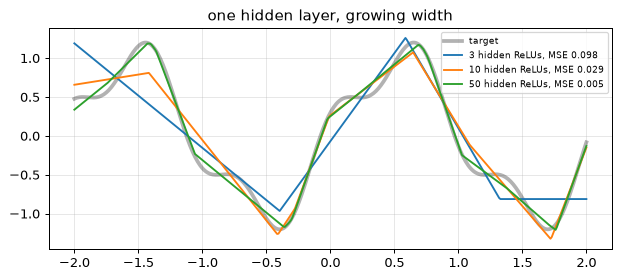

In [48]:
target = lambda x: np.sin(3 * x) + 0.3 * np.cos(9 * x)
xu = torch.linspace(-2, 2, 400).unsqueeze(1); yu = torch.tensor(target(xu.numpy()), dtype=torch.float32)
plt.figure(figsize=(7, 3.2)); plt.plot(xu, yu, "k", lw=3, alpha=0.3, label="target")
for width in [3, 10, 50]:
    torch.manual_seed(0)
    net_u = nn.Sequential(nn.Linear(1, width), nn.ReLU(), nn.Linear(width, 1))
    with torch.no_grad():                                  # place each hinge somewhere inside [-2, 2] so none start dead
        w_ = torch.where(torch.rand(width) < 0.5, -1.0, 1.0) * (0.5 + 1.5 * torch.rand(width))
        kinks = torch.rand(width) * 4 - 2
        net_u[0].weight.copy_(w_.unsqueeze(1)); net_u[0].bias.copy_(-w_ * kinks)
    opt_u = torch.optim.Adam(net_u.parameters(), lr=1e-2)
    sched_u = torch.optim.lr_scheduler.CosineAnnealingLR(opt_u, T_max=1500)
    for _ in range(1500):
        opt_u.zero_grad(); loss_u = F.mse_loss(net_u(xu), yu); loss_u.backward(); opt_u.step(); sched_u.step()
    plt.plot(xu, net_u(xu).detach(), label=f"{width} hidden ReLUs, MSE {loss_u.item():.3f}")
plt.legend(fontsize=7); plt.title("one hidden layer, growing width"); plt.tight_layout(); plt.show()

### 13.3 Double descent

**What it is.** Classical theory says test error is U-shaped in model size (Section 13.1). Modern over-parameterised models show **double descent** (Belkin et al., 2019; Nakkiran et al., 2019): test error goes down, then **peaks** around the **interpolation threshold** (where the model has just enough parameters to fit the training set exactly, including its noise), then goes **down again** as the model grows further.

**Why the peak.** At the threshold there is exactly one way to fit every noisy point, and that solution has to bend wildly. With many more parameters there are infinitely many perfect fits, and gradient descent (or the minimum-norm solution) picks a smooth one.

Demo: regression with $p$ random ReLU features and the **minimum-norm** least-squares fit (`np.linalg.pinv`), with $n = 40$ training points. Only the output layer is fitted, so this is a 2-layer network with a frozen random first layer. Whether the far right of the curve ends up below the classical sweet spot on the left depends on the noise level, the data and any regularisation; the peak at $p \approx n$ is the robust part.

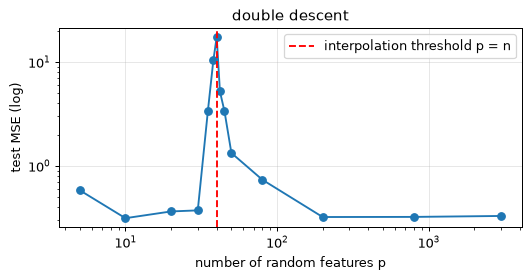

test MSE by p: {5: 0.582, 10: 0.314, 20: 0.364, 30: 0.373, 35: 3.407, 38: 10.369, 40: 17.469, 42: 5.214, 45: 3.371, 50: 1.332, 80: 0.736, 200: 0.322, 800: 0.323, 3000: 0.329}


In [49]:
n_dd, d_dd = 40, 5
rdd = np.random.default_rng(0)                                        # own generator so the demo is reproducible
w_dd = rdd.normal(size=d_dd)
def dd_data(m): X_ = rdd.normal(size=(m, d_dd)); return X_, np.sin(X_ @ w_dd) + 0.3 * rdd.normal(size=m)
Xtr_dd, ytr_dd = dd_data(n_dd); Xte_dd, yte_dd = dd_data(1000)
W_feat = rdd.normal(size=(d_dd, 3000)) / np.sqrt(d_dd)                # fixed random first layer
ps = [5, 10, 20, 30, 35, 38, 40, 42, 45, 50, 80, 200, 800, 3000]
test_err = []
for p_ in ps:
    Ftr = np.maximum(Xtr_dd @ W_feat[:, :p_], 0); Fte = np.maximum(Xte_dd @ W_feat[:, :p_], 0)
    beta = np.linalg.pinv(Ftr) @ ytr_dd                                # minimum-norm least squares
    test_err.append(np.mean((Fte @ beta - yte_dd) ** 2))
plt.loglog(ps, test_err, "o-"); plt.axvline(n_dd, ls="--", c="r", label="interpolation threshold p = n")
plt.xlabel("number of random features p"); plt.ylabel("test MSE (log)"); plt.legend(); plt.title("double descent")
plt.tight_layout(); plt.show()
print("test MSE by p:", {p_: round(float(e), 3) for p_, e in zip(ps, test_err)})

### 13.4 Grokking (described)

**What it is.** **Grokking** (Power et al., 2022) is when a network first **memorises** a small algorithmic training set (for example, modular addition $a + b \bmod 97$), reaching 100% training accuracy with chance-level validation accuracy, and then, after many more steps (often 10-100x longer), validation accuracy suddenly jumps to near 100%.

**Why it happens (current understanding).** Memorising and generalising solutions both fit the training data, but the generalising one (which, for modular addition, uses Fourier-like features) has much smaller weight norm. Weight decay slowly pushes the model from the memorising solution towards the simpler one. Grokking is very sensitive to weight decay and dataset size.

**Practical lessons.** "Validation is flat" does not always mean "stop now" on small algorithmic tasks; weight decay matters; and training loss alone cannot tell you which kind of solution the model found.

### 13.5 Loss-landscape slices and sharp vs flat minima

**What it is.** The loss is a function of millions of weights, so we look at low-dimensional **slices**:
- **1D linear interpolation** (Goodfellow et al., 2015): $L\big((1-\alpha)\theta_0 + \alpha\theta_1\big)$ between the initial and final weights.
- **2D random-direction slice** (Li et al., 2018): $L(\theta^* + a\,d_1 + b\,d_2)$ with random directions $d_1, d_2$ rescaled to match each layer's weight norm ("filter normalisation"), so slices of different models are comparable.

**Sharp vs flat minima.** A **flat** minimum is one where the loss stays low in a wide region around it; a **sharp** one rises quickly. A common intuition (Hochreiter and Schmidhuber, 1997; Keskar et al., 2017) is that flat minima generalise better, because the test loss surface is a slightly shifted version of the training one, and a shift hurts a sharp minimum more. It is a useful heuristic rather than a law (sharpness can be changed by rescaling weights without changing the function, Dinh et al., 2017). Methods such as **SAM** (sharpness-aware minimisation) explicitly look for flat regions.

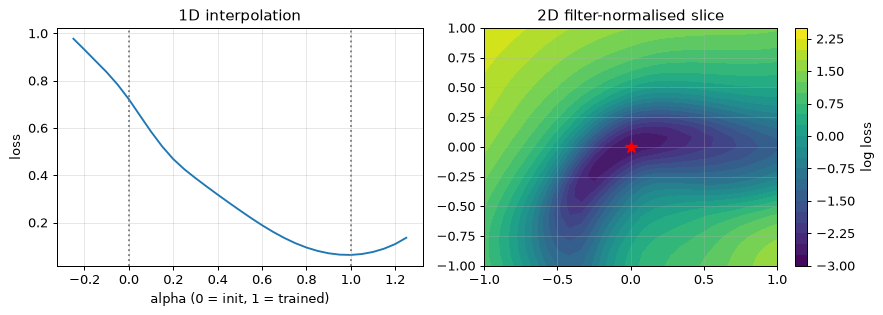

In [50]:
# Train the moons MLP from Section 7, then slice its loss landscape
model_ls = make_mlp(seed=1); theta_init = copy.deepcopy(model_ls.state_dict())
opt_ls = torch.optim.Adam(model_ls.parameters(), lr=1e-2)
for _ in range(300):
    opt_ls.zero_grad(); F.cross_entropy(model_ls(Xm_t), ym_t).backward(); opt_ls.step()
theta_star = copy.deepcopy(model_ls.state_dict())

def loss_at(state):
    model_ls.load_state_dict(state)
    with torch.no_grad(): return F.cross_entropy(model_ls(Xm_t), ym_t).item()

alphas = np.linspace(-0.25, 1.25, 31)
interp = [loss_at({k: (1 - a_) * theta_init[k] + a_ * theta_star[k] for k in theta_star}) for a_ in alphas]

torch.manual_seed(0)
def filter_normalised_direction():
    d_ = {}
    for k, v in theta_star.items():
        r_ = torch.randn_like(v)
        d_[k] = r_ / (r_.norm() + 1e-10) * v.norm() if v.ndim > 1 else torch.zeros_like(v)   # skip biases
    return d_
d1, d2 = filter_normalised_direction(), filter_normalised_direction()
grid = np.linspace(-1, 1, 25)
surface = np.array([[loss_at({k: theta_star[k] + a_ * d1[k] + b_ * d2[k] for k in theta_star}) for a_ in grid] for b_ in grid])
model_ls.load_state_dict(theta_star)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(alphas, interp); ax[0].axvline(0, c="gray", ls=":"); ax[0].axvline(1, c="gray", ls=":")
ax[0].set_xlabel("alpha (0 = init, 1 = trained)"); ax[0].set_title("1D interpolation"); ax[0].set_ylabel("loss")
cs = ax[1].contourf(grid, grid, np.log(surface), levels=20, cmap="viridis"); plt.colorbar(cs, ax=ax[1], label="log loss")
ax[1].plot(0, 0, "r*", ms=10); ax[1].set_title("2D filter-normalised slice"); plt.tight_layout(); plt.show()

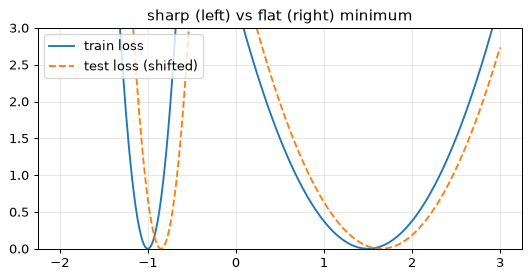

sharp minimum: train loss 0.000, test loss 0.675
flat  minimum: train loss 0.000, test loss 0.034


In [51]:
# Sharp vs flat: a 1D toy loss with two equally deep minima. "Test" loss = the same curve shifted by 0.15.
train_loss = lambda w: np.minimum(30 * (w + 1) ** 2, 1.5 * (w - 1.5) ** 2)    # sharp min at -1, flat min at 1.5
test_loss  = lambda w: train_loss(w - 0.15)
wgrid = np.linspace(-2, 3, 500)
plt.plot(wgrid, train_loss(wgrid), label="train loss"); plt.plot(wgrid, test_loss(wgrid), "--", label="test loss (shifted)")
plt.ylim(0, 3); plt.legend(); plt.title("sharp (left) vs flat (right) minimum"); plt.tight_layout(); plt.show()
for name, w_min in [("sharp", -1.0), ("flat ", 1.5)]:
    print(f"{name} minimum: train loss {train_loss(w_min):.3f}, test loss {test_loss(w_min):.3f}")

## 14. A complete training loop in PyTorch

Everything above in one place: data split and loaders, a model with normalisation and dropout, a loss with label smoothing, AdamW with parameter groups, warmup + cosine schedule, gradient clipping (with the norm logged), an evaluation loop in `eval()` mode under `torch.no_grad()`, early stopping on validation loss, and saving / restoring a checkpoint that includes the optimiser and scheduler state so training could be resumed. A production version with config files, logging and mixed precision is in [16 training pipeline](16_industry_pytorch_training_pipeline.ipynb).

```mermaid
flowchart LR
    D[Data loader] --> FWD[Forward pass] --> L[Loss]
    L --> BWD[Backward pass] --> C[Clip gradient norm] --> O[Optimiser step] --> S[Scheduler step]
    S --> D
    O -. every epoch .-> E[Evaluate on validation] --> K{Best so far?}
    K -- yes --> CK[Save checkpoint]
    K -- no, patience used up --> STOP[Stop and restore best]
```

In [52]:
# ---- 1. Data: a 3-class spiral (not linearly separable), split into train / validation
def make_spiral(n_per_class=300, classes=3, noise=0.25, seed=0):
    r_ = np.random.default_rng(seed); X_, y_ = [], []
    for c in range(classes):
        t = np.linspace(0, 1, n_per_class); angle = t * 4 + c * 2 * np.pi / classes + r_.normal(0, noise, n_per_class) * t
        X_.append(np.c_[t * np.cos(angle), t * np.sin(angle)]); y_.append(np.full(n_per_class, c))
    return np.vstack(X_).astype(np.float32), np.concatenate(y_)
Xs, ys = make_spiral()
perm = rng.permutation(len(Xs)); n_train = int(0.8 * len(Xs))
train_ds = TensorDataset(torch.tensor(Xs[perm[:n_train]]), torch.tensor(ys[perm[:n_train]]))
val_ds = TensorDataset(torch.tensor(Xs[perm[n_train:]]), torch.tensor(ys[perm[n_train:]]))
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False)

# ---- 2. Model: pre-norm residual MLP blocks
class Block(nn.Module):
    def __init__(self, d, p_drop):
        super().__init__(); self.norm = nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(p_drop), nn.Linear(2 * d, d))
    def forward(self, x): return x + self.ff(self.norm(x))

class Classifier(nn.Module):
    def __init__(self, d_in=2, d=64, n_blocks=3, n_classes=3, p_drop=0.1):
        super().__init__()
        self.embed = nn.Linear(d_in, d)
        self.blocks = nn.Sequential(*[Block(d, p_drop) for _ in range(n_blocks)])
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, n_classes))   # final norm for pre-norm models
    def forward(self, x): return self.head(self.blocks(self.embed(x)))

torch.manual_seed(SEED)
model = Classifier()
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")

parameters: 50,627


In [53]:
# ---- 3. Loss, optimiser (no weight decay on biases / norm gains), warmup + cosine schedule
EPOCHS, PEAK_LR, WD, CLIP = 60, 3e-3, 0.05, 1.0
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.05)
decay_p = [p for n, p in model.named_parameters() if p.ndim > 1]
nodecay_p = [p for n, p in model.named_parameters() if p.ndim <= 1]
optimizer = torch.optim.AdamW([{"params": decay_p, "weight_decay": WD}, {"params": nodecay_p, "weight_decay": 0.0}],
                              lr=PEAK_LR, betas=(0.9, 0.999))
total_steps = EPOCHS * len(train_loader); warmup_steps = int(0.05 * total_steps)
def lr_lambda(step):                                         # multiplier on PEAK_LR
    if step < warmup_steps: return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * progress))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

# ---- 4. Evaluation
@torch.no_grad()                                             # no graph, less memory, faster
def evaluate(model, loader):
    model.eval()                                             # dropout off, norms in inference mode
    total_loss, correct, count = 0.0, 0, 0
    for xb, yb in loader:
        logits = model(xb)
        total_loss += F.cross_entropy(logits, yb, reduction="sum").item()
        correct += (logits.argmax(1) == yb).sum().item(); count += len(yb)
    return total_loss / count, correct / count

# ---- 5. Training loop with clipping, logging, early stopping and checkpointing
ckpt_dir = tempfile.mkdtemp(); ckpt_path = os.path.join(ckpt_dir, "best.pt")
history = {"train_loss": [], "val_loss": [], "val_acc": [], "grad_norm": [], "lr": []}
best_val, patience, bad = float("inf"), 15, 0
for epoch in range(EPOCHS):
    model.train(); running = 0.0
    for xb, yb in train_loader:
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)   # returns the norm BEFORE clipping
        optimizer.step(); scheduler.step()
        if not torch.isfinite(loss): raise RuntimeError(f"non-finite loss at epoch {epoch}")
        running += loss.item() * len(yb)
        history["grad_norm"].append(gnorm.item()); history["lr"].append(scheduler.get_last_lr()[0])
    val_loss, val_acc = evaluate(model, val_loader)
    history["train_loss"].append(running / len(train_ds)); history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
    if val_loss < best_val - 1e-4:
        best_val, bad = val_loss, 0
        torch.save({"epoch": epoch, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(), "val_loss": val_loss}, ckpt_path)
    else:
        bad += 1
        if bad >= patience: print(f"early stop at epoch {epoch}"); break
    if epoch % 10 == 0 or epoch == EPOCHS - 1:
        print(f"epoch {epoch:3d}  train {history['train_loss'][-1]:.4f}  val {val_loss:.4f}  acc {val_acc:.3f}  lr {history['lr'][-1]:.2e}")

epoch   0  train 1.0048  val 0.7532  acc 0.639  lr 1.08e-03


epoch  10  train 0.2733  val 0.0802  acc 0.983  lr 2.86e-03


epoch  20  train 0.2358  val 0.0590  acc 0.989  lr 2.32e-03


epoch  30  train 0.1866  val 0.0501  acc 0.994  lr 1.54e-03
early stop at epoch 32


restored epoch 17 -> val loss 0.0396 (saved 0.0396), val accuracy 1.000


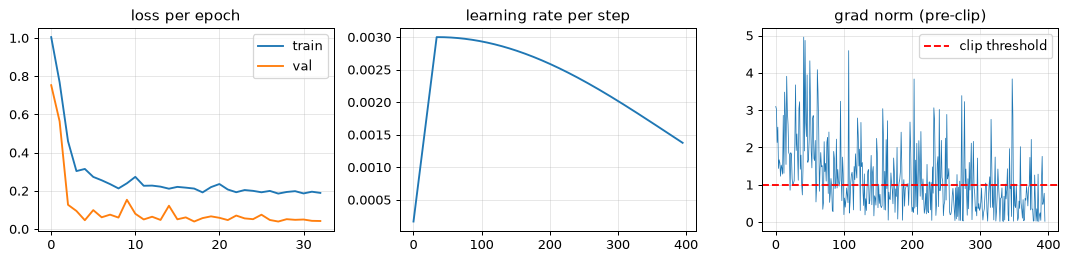

pre-clip grad norm: median 0.97; steps clipped: first half 65%, second half 32%


In [54]:
# ---- 6. Restore the best checkpoint (this is also how you resume: load model, optimizer and scheduler states)
ckpt = torch.load(ckpt_path, weights_only=True)
model.load_state_dict(ckpt["model"]); optimizer.load_state_dict(ckpt["optimizer"]); scheduler.load_state_dict(ckpt["scheduler"])
print(f"restored epoch {ckpt['epoch']} -> val loss {evaluate(model, val_loader)[0]:.4f} (saved {ckpt['val_loss']:.4f}), "
      f"val accuracy {evaluate(model, val_loader)[1]:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val"); ax[0].set_title("loss per epoch"); ax[0].legend()
ax[1].plot(history["lr"]); ax[1].set_title("learning rate per step")
ax[2].plot(history["grad_norm"], lw=0.6); ax[2].axhline(CLIP, c="r", ls="--", label="clip threshold"); ax[2].set_title("grad norm (pre-clip)"); ax[2].legend()
plt.tight_layout(); plt.show()
gn_ = np.array(history["grad_norm"]); half = len(gn_) // 2
print(f"pre-clip grad norm: median {np.median(gn_):.2f}; steps clipped: first half {np.mean(gn_[:half] > CLIP):.0%}, second half {np.mean(gn_[half:] > CLIP):.0%}")

**Reading the results.** The training loss sits above the validation loss here. That is expected, not a bug: the training loss includes label smoothing (its minimum is above 0) and is measured with dropout on, while validation uses plain cross-entropy in `eval()` mode. On a tiny model with small batches, gradient norms near the clip threshold are common; on a large run, a high and rising clipped fraction is a warning sign worth investigating.

### 14.1 Training diagnostics checklist

Work through this list, roughly in order, when a model does not train well.

| Check | How | What a problem looks like | Typical fix |
|---|---|---|---|
| Loss at step 0 | for $K$ balanced classes it should be about $\log K$ | much higher: bad init or label bug | zero/small init of the last layer; check labels |
| Overfit one batch | train on a single batch of 8-32 for ~200 steps | cannot reach near-zero loss | bug in model, loss, labels or the optimiser step |
| Shapes and broadcasting | print shapes; assert expected shapes | silent broadcasting, e.g. `(B,1) - (B,)` gives `(B,B)` | `squeeze`/`unsqueeze` explicitly |
| Train vs eval mode | `model.train()` / `model.eval()` | val metrics change with batch size or vary run to run | call `eval()` and use `torch.no_grad()` |
| `zero_grad` | once per optimiser step | loss explodes (gradients keep adding up) | call `optimizer.zero_grad()` each step (unless accumulating on purpose) |
| Learning rate | LR range test; try 3x up and down | flat loss (too low) or spikes / NaN (too high) | tune LR, add warmup |
| Gradient norm | log it each step (pre-clipping) | always clipped, growing, or tiny | lower LR, check init / norms / residuals |
| Activation statistics | mean/std per layer; fraction of zero ReLUs | vanishing, exploding, dead units | He/Xavier init, normalisation, Leaky/GELU |
| Train vs val curves | plot both | val rises while train falls = overfitting; both high = underfitting | regularise / more data vs bigger model / train longer |
| Data pipeline | look at actual batches, labels and augmentations | wrong labels, leakage, unshuffled data | fix the loader; shuffle training data |
| Numerics | `torch.isfinite` on loss and grads | NaN / inf | stable losses, BF16 instead of FP16, clipping |
| Reproducibility | fixed seeds; compare two runs | unexplained run-to-run differences | seed everything; note non-deterministic kernels |
| Baseline | compare with a trivial model (majority class, linear) | deep model is not better | revisit features, data and the task framing |

Karpathy's blog post "A Recipe for Training Neural Networks" (2019) is a good longer version of this list. [18 from scratch, Section 10](18_neural_networks_from_scratch_numpy.ipynb) shows several of these checks as code.

## Recap: cheat sheet

| Topic | Key formula | Remember |
|---|---|---|
| Layer | $Z = XW + b$, $A = \phi(Z)$ | shapes $(B,d_\text{in})(d_\text{in},d_\text{out})$; bias broadcasts |
| MSE / MAE / Huber | $r^2$, $\lvert r\rvert$, quadratic then linear | mean vs median; Huber for outliers |
| Cross-entropy | $-z_c + \log\sum_j e^{z_j}$ | pass logits; log-sum-exp for stability |
| BCE with logits | $\max(z,0) - zy + \log(1+e^{-\lvert z\rvert})$ | one sigmoid per label |
| Label smoothing | $q = (1-\varepsilon)\,\text{onehot} + \varepsilon/K$ | $\varepsilon \approx 0.1$ |
| Focal | $-\alpha(1-p_t)^\gamma\log p_t$ | heavy imbalance, $\gamma=2$ |
| KL | $\sum p\log(p/q)$ | $H(p,q) = H(p) + \text{KL}$ |
| InfoNCE | CE over similarity matrix $/\tau$, target = diagonal | more negatives help |
| Triplet | $\max(0, d(a,p) - d(a,n) + m)$ | hard negatives |
| Chain rule | $\partial L/\partial w = \partial L/\partial a \cdot \partial a/\partial z \cdot \partial z/\partial w$ | gradients add over paths |
| Softmax + CE grad | $\partial L/\partial Z = (P - Y)/B$ | fused in frameworks |
| Linear-layer grads | $dW = X^\top dZ$, $dX = dZ\,W^\top$, $db = \sum dZ$ | grad shape = param shape |
| Grad check | $(L(\theta+\epsilon)-L(\theta-\epsilon))/2\epsilon$ | float64, relative error < 1e-6 |
| Xavier / He | $\operatorname{Var}(w) = 2/(n_\text{in}+n_\text{out})$ / $2/n_\text{in}$ | tanh / ReLU |
| Momentum | $m \leftarrow \beta m + g$; $\theta \leftarrow \theta - \eta m$ | $\beta = 0.9$ |
| Adam | $\hat m/(\sqrt{\hat v}+\epsilon)$ with $\hat m = m/(1-\beta_1^t)$ | bias correction |
| AdamW | Adam step, then $\theta \leftarrow \theta - \eta\lambda\theta$ | decoupled decay |
| GD stability | $\eta < 2/\lambda_\text{max}$ | sharpness limits LR |
| Warmup + cosine | linear up, then $\tfrac12(1+\cos\pi t/T)$ | LLM default; WSD for open-ended runs |
| Linear scaling | $B \to kB \Rightarrow \eta \to k\eta$ (SGD) | $\sqrt{k}$ for Adam as a start |
| Gradient noise | $\operatorname{Var} \propto 1/B$ | diminishing returns |
| Grad accumulation | sum of $\nabla(\ell_j/k)$ = big-batch grad | BN caveat |
| BatchNorm / LayerNorm / RMSNorm | $\gamma(x-\mu)/\sqrt{\sigma^2+\epsilon}+\beta$ over batch / features; RMS: $\gamma x/\text{rms}(x)$ | `eval()` for BN |
| Pre-norm | $x + F(\text{Norm}(x))$ | clean residual path |
| Inverted dropout | $m\odot h/(1-p)$ | identity at eval |
| Mixup | $\lambda x_i + (1-\lambda)x_j$, $\lambda\sim\text{Beta}(\alpha,\alpha)$ | soft labels too |
| Clip by norm | $g \cdot \min(1, c/\lVert g\rVert)$ | log the pre-clip norm |
| Residual | $\partial x_{l+1}/\partial x_l = I + \partial F/\partial x_l$ | gradient highway |
| Loss scaling | $g = \nabla(SL)/S$ | FP16 only; BF16 has FP32 range |
| Training memory | ~16 bytes/param (mixed + AdamW) + activations | checkpointing trades compute for memory |
| Training compute | $C \approx 6ND$ | Chinchilla: ~20 tokens per parameter |
| Bias-variance | $\text{bias}^2 + \text{variance} + \sigma^2$ | double descent past interpolation |

## Interview questions

**1. Why do we pass logits, not probabilities, to `CrossEntropyLoss`?**
It computes log-softmax internally with the log-sum-exp trick, which is numerically stable. Applying softmax first and then taking a log can produce `log(0) = -inf` for very confident wrong predictions, and the gradient of the fused version is the simple, well-behaved $p - y$.

**2. Why does backprop cost only about 2x the forward pass?**
Reverse-mode differentiation reuses the upstream gradient: each operation does a fixed amount of work per backward visit, so one backward sweep produces the gradient for all parameters at once. Per linear layer that is two matmuls (input gradient and weight gradient), each as large as the forward one, which is also where the $6ND$ rule comes from.

**3. What goes wrong if you initialise all weights to zero?**
Every hidden unit in a layer computes the same output and receives the same gradient, so they stay identical forever (symmetry is never broken). With ReLU and zero weights the gradients to earlier layers are also zero.

**4. Adam with L2 vs AdamW?**
With L2, the decay term is added to the gradient and then divided by $\sqrt{\hat v}$, so parameters with large gradients are barely regularised. AdamW applies $\theta \leftarrow \theta - \eta\lambda\theta$ separately, giving the same relative decay to every weight. AdamW usually generalises better and makes LR and weight decay easier to tune independently.

**5. Why warmup?**
At the start, weights are random, the loss surface can be very sharp, and Adam's second-moment estimates are based on very few gradients. A small LR for the first steps avoids huge, badly-scaled updates and early divergence, especially with large batches and post-norm transformers.

**6. Why do transformers use LayerNorm/RMSNorm instead of BatchNorm?**
They normalise each token independently, so they do not depend on batch size, padding or sequence length, and they behave the same in training and in one-token-at-a-time generation.

**7. How does gradient accumulation differ from a truly larger batch?**
The gradient is identical if each micro-batch loss is scaled by $1/k$, except for layers that use batch statistics (BatchNorm) and for per-token averaging with variable lengths. It costs more time per update, since micro-batches run one after another.

**8. FP16 vs BF16 for training?**
Both use 2 bytes. BF16 keeps FP32's 8-bit exponent, so it has the same range and needs no loss scaling, but has lower precision. FP16 has more precision but a small range (max 65504), so gradients underflow without loss scaling and activations can overflow.

**9. How much GPU memory does full fine-tuning of a 7B model with AdamW in mixed precision need?**
About 16 bytes per parameter for weights, gradients and optimiser states, so about 112 GB, plus activations. Options: sharding (ZeRO/FSDP), gradient checkpointing, 8-bit optimisers, or parameter-efficient fine-tuning ([12 PEFT](12_advanced_peft.ipynb)).

**10. Your training loss suddenly becomes NaN. What do you do?**
Find the first non-finite step; check the data batch at that step; look at the gradient norm just before it; check for `log`/`sqrt`/division of zero and FP16 overflow; use anomaly detection and forward hooks; then lower the LR or add warmup and clipping, and switch to BF16.

## Further reading

**Books and courses**
- Goodfellow, Bengio and Courville, *Deep Learning* (MIT Press, 2016), free at deeplearningbook.org. Chapters 6-8 cover most of this notebook.
- Zhang, Lipton, Li and Smola, *Dive into Deep Learning*, d2l.ai (free, with runnable PyTorch code).
- Andrej Karpathy, *micrograd* (github.com/karpathy/micrograd) and the "Neural Networks: Zero to Hero" lecture series; blog post "A Recipe for Training Neural Networks" (2019).

**Optimisers and learning rates**
- Kingma and Ba, "Adam: A Method for Stochastic Optimization" (2014), arXiv:1412.6980.
- Loshchilov and Hutter, "Decoupled Weight Decay Regularization" (AdamW, 2017), arXiv:1711.05101.
- Smith, "Cyclical Learning Rates for Training Neural Networks" (LR range test, 2015), arXiv:1506.01186.
- Smith and Topin, "Super-Convergence: Very Fast Training of Neural Networks Using Large Learning Rates" (one-cycle, 2017), arXiv:1708.07120.
- Goyal et al., "Accurate, Large Minibatch SGD: Training ImageNet in 1 Hour" (linear scaling rule, 2017), arXiv:1706.02677.
- Chen et al., "Symbolic Discovery of Optimization Algorithms" (Lion, 2023), arXiv:2302.06675; Shazeer and Stern, "Adafactor" (2018), arXiv:1804.04235; Gupta, Koren and Singer, "Shampoo" (2018), arXiv:1802.09568; Keller Jordan, "Muon" (blog post, 2024).

**Initialisation, normalisation, regularisation**
- Glorot and Bengio, "Understanding the difficulty of training deep feedforward neural networks" (AISTATS 2010).
- He et al., "Delving Deep into Rectifiers" (He init, 2015), arXiv:1502.01852; Saxe, McClelland and Ganguli (orthogonal init, 2013), arXiv:1312.6120.
- Ioffe and Szegedy, "Batch Normalization" (2015), arXiv:1502.03167; Ba, Kiros and Hinton, "Layer Normalization" (2016), arXiv:1607.06450; Zhang and Sennrich, "Root Mean Square Layer Normalization" (2019), arXiv:1910.07467; Wu and He, "Group Normalization" (2018), arXiv:1803.08494; Xiong et al., "On Layer Normalization in the Transformer Architecture" (2020), arXiv:2002.04745.
- Srivastava et al., "Dropout" (JMLR 2014); Zhang et al., "mixup" (2017), arXiv:1710.09412; Huang et al., "Deep Networks with Stochastic Depth" (2016), arXiv:1603.09382.
- Lin et al., "Focal Loss for Dense Object Detection" (2017), arXiv:1708.02002; van den Oord et al., "Representation Learning with Contrastive Predictive Coding" (InfoNCE, 2018), arXiv:1807.03748; Graves et al., "Connectionist Temporal Classification" (ICML 2006); Shazeer, "GLU Variants Improve Transformer" (SwiGLU, 2020), arXiv:2002.05202.

**Stability, numerics and scale**
- Pascanu, Mikolov and Bengio, "On the difficulty of training recurrent neural networks" (2012), arXiv:1211.5063.
- Micikevicius et al., "Mixed Precision Training" (2017), arXiv:1710.03740; Micikevicius et al., "FP8 Formats for Deep Learning" (2022), arXiv:2209.05433.
- Chen et al., "Training Deep Nets with Sublinear Memory Cost" (gradient checkpointing, 2016), arXiv:1604.06174; Korthikanti et al., "Reducing Activation Recomputation in Large Transformer Models" (2022), arXiv:2205.05198.
- Kaplan et al., "Scaling Laws for Neural Language Models" (2020), arXiv:2001.08361.
- Hoffmann et al., "Training Compute-Optimal Large Language Models" (Chinchilla, 2022), arXiv:2203.15556.

**Generalisation**
- Belkin et al., "Reconciling modern machine learning practice and the bias-variance trade-off" (double descent, 2018), arXiv:1812.11118; Nakkiran et al., "Deep Double Descent" (2019), arXiv:1912.02292.
- Power et al., "Grokking: Generalization Beyond Overfitting on Small Algorithmic Datasets" (2022), arXiv:2201.02177.
- Li et al., "Visualizing the Loss Landscape of Neural Nets" (2017), arXiv:1712.09913; Keskar et al., "On Large-Batch Training for Deep Learning: Generalization Gap and Sharp Minima" (2016), arXiv:1609.04836.

**In this repo:** [00 PyTorch from zero](00_start_here_pytorch_from_zero.ipynb), [01 fundamentals](01_neural_network_fundamentals.ipynb), [02 optimizers](02_optimizers.ipynb), [18 from scratch in NumPy](18_neural_networks_from_scratch_numpy.ipynb), [11 distributed training](11_distributed_training.ipynb), [13 quantization](13_quantization_and_compression_advanced.ipynb), [14/02 calculus](../14_Mathematics/02_calculus.ipynb), [14/06 optimization](../14_Mathematics/06_optimization.ipynb), [14/11 matrix calculus and autodiff](../14_Mathematics/11_matrix_calculus_and_autodiff_from_scratch.ipynb).

In [55]:
print(f"Notebook finished in {time.time() - T_START:.0f} s")

Notebook finished in 18 s
